<a href="https://colab.research.google.com/github/steevesolomon-eng/senate-polls-vs-markets/blob/main/senate_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 2026 Senate: Polling vs Prediction Markets (clean notebook)

**Run top to bottom.** Nothing is downloaded or uploaded in a normal run: every dataset is read from Google Drive (`senate_project`).

- Drive asks for permission **once per new session** (after Colab disconnects), not on every re-run.
- Section 9 (REFRESH) is the only part that downloads Polymarket data. It is skipped unless `REFRESH = True` in the setup cell.
- To re-pull election results, set `FETCH_RESULTS = True` in the results cell, then point `RESULTS_JSON` at the new file.
- Secrets needed only if the FEC cache file is missing: `GOV_DATA_API_KEY` (Colab Secrets).

In [103]:
# SETUP. Run first in every session. Downloads nothing.
import os, re, io, json, time, glob, shutil, unicodedata, subprocess
import numpy as np, pandas as pd, requests
from google.colab import drive

REFRESH   = False   # True ONLY to re-download Polymarket data (Section 9)
USE_DRIVE = False   # False = clone the GitHub repo (default); True = your own Drive folder "senate_project"
REPO_URL  = "https://github.com/steevesolomon-eng/senate-polls-vs-markets"

if USE_DRIVE:
    if not os.path.isdir("/content/drive/MyDrive"):
        drive.mount("/content/drive")      # permission prompt appears once per new session
    DATA = "/content/drive/MyDrive/senate_project"
else:
    if not os.path.isdir("/content/repo"):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "/content/repo"], check=True)
    DATA = "/content/repo/data"
os.makedirs(DATA, exist_ok=True)

GAMMA_BASE = "https://gamma-api.polymarket.com"
states = [
    "Alabama", "Alaska", "Arkansas", "Colorado", "Delaware", "Florida", "Georgia", "Idaho",
    "Illinois", "Iowa", "Kansas", "Kentucky", "Louisiana", "Maine", "Massachusetts", "Michigan",
    "Minnesota", "Mississippi", "Montana", "Nebraska", "New Jersey", "New Mexico","New Hampshire",
    "North Carolina", "Ohio", "Oklahoma", "Oregon", "Rhode Island", "South Carolina", "South Dakota",
    "Tennessee", "Texas", "Virginia", "West Virginia", "Wyoming"
]

def normalize(text):
    return re.sub(r"[^a-z0-9]+", " ", str(text).lower()).strip()

def parse_if_json(value):
    if isinstance(value, str):
        try:
            return json.loads(value)
        except json.JSONDecodeError:
            return value
    return value

print("Data folder:", DATA)
print("Files:", sorted(os.listdir(DATA)))

Drive folder: /content/repo/data
Files: []


In [ ]:
# LOAD SAVED RAW DATA FROM DRIVE (no downloads)
if os.path.exists(dpath("polling_desk_merged.csv")):
    polls_raw = pd.read_csv(dpath("polling_desk_merged.csv"))
else:
    from google.colab import files            # only if the file is not on Drive yet
    up = files.upload()
    fname = [k for k in up if k.lower().endswith(".csv")][0]
    polls_raw = pd.read_csv(io.BytesIO(up[fname]))
    polls_raw.to_csv(dpath("polling_desk_merged.csv"), index=False)

for f in ("polymarket_2026_senate_raw.csv", "polymarket_senate_market_register.csv"):
    if not os.path.exists(dpath(f)):
        raise FileNotFoundError(f"{f} not on Drive. Set REFRESH = True in 1st Cell and run Section 9.")

poly_history_all = pd.read_csv(dpath("polymarket_2026_senate_raw.csv"))
poly_history_all["timestamp_utc"] = pd.to_datetime(poly_history_all["timestamp_utc"], utc=True)
market_register = pd.read_csv(dpath("polymarket_senate_market_register.csv"), dtype={"yes_token_id": str})

print("polls_raw            :", polls_raw.shape, "(expect 2019 rows x 13)")
print("poly_history_all     :", poly_history_all.shape, "(expect 48,786 rows)")
print("market_register      :", market_register.shape, "(expect 34 markets)")

polls_raw            : (2189, 13) (expect 2019 rows x 13)
poly_history_all     : (49273, 9) (expect 48,786 rows)
market_register      : (34, 8) (expect 34 markets)


## Section 1: Polling data and the 25-state sample

In [ ]:
# Audit Polling Desk data

polls_audit = polls_raw.copy()

# Convert dates for inspection
polls_audit["start_date"] = pd.to_datetime(
    polls_audit["start_date"],
    format="mixed",
    errors="coerce"
)

polls_audit["end_date"] = pd.to_datetime(
    polls_audit["end_date"],
    format="mixed",
    errors="coerce"
)

polls_audit["pct"] = pd.to_numeric(
    polls_audit["pct"],
    errors="coerce"
)

print("TOTAL ROWS:", len(polls_audit))
print("UNIQUE POLLS:", polls_audit["poll_id"].nunique())
print("UNIQUE RACES:", polls_audit["subject"].nunique())

print("\nPOPULATION BREAKDOWN:")
display(polls_audit["population"].value_counts())

print("\nDATE COVERAGE:")
print("First:", polls_audit["start_date"].min())
print("Last:", polls_audit["end_date"].max())

print("\nRACE COVERAGE:")
display(
    polls_audit.groupby("subject")["poll_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("\nMISSING VALUES:")
display(polls_audit.isna().sum())

print("\nFIRST FIVE RECORDS:")
display(polls_audit.head())

TOTAL ROWS: 2189
UNIQUE POLLS: 783
UNIQUE RACES: 35

POPULATION BREAKDOWN:


,count
population,
lv,2189



DATE COVERAGE:
First: 2025-10-24 00:00:00
Last: 2026-11-02 00:00:00

RACE COVERAGE:


,poll_id
subject,
2026 Michigan,95
2026 Texas,91
2026 Maine,60
2026 North Carolina,45
2026 Iowa,45
2026 Florida,43
2026 Ohio,40
2026 Minnesota,39
2026 Montana,32



MISSING VALUES:


,0
poll_id,0
poll_type,0
subject,0
pollster,0
start_date,0
end_date,0
sample_size,36
population,0
sponsors,1271
internal,0



FIRST FIVE RECORDS:


,poll_id,poll_type,subject,pollster,start_date,end_date,sample_size,population,sponsors,internal,choice,pct,source_url
0,nyt-073fdbf9aac1,us-senator,2026 Ohio,ActiVote,2026-10-18,2026-10-31,400.0,lv,NaN,False,Sherrod Brown,50.2,https://www.activote.net/polls/2026/oh-u-s-sen...
1,nyt-073fdbf9aac1,us-senator,2026 Ohio,ActiVote,2026-10-18,2026-10-31,400.0,lv,NaN,False,Jon Husted,49.8,https://www.activote.net/polls/2026/oh-u-s-sen...
2,us-202act4459517f,us-senator,2026 Illinois,ActiVote,2026-10-21,2026-10-30,400.0,lv,NaN,False,Juliana Stratton,55.6,https://www.activote.net/polls/2026/il-u-s-sen...
3,us-202act4459517f,us-senator,2026 Illinois,ActiVote,2026-10-21,2026-10-30,400.0,lv,NaN,False,Don Tracy,44.4,https://www.activote.net/polls/2026/il-u-s-sen...
4,nyt-6f9d149aae66,us-senator,2026 Florida,Big Data Poll,2026-10-26,2026-10-30,1067.0,lv,1776 Law Center | Public Polling Project,False,Ashley Moody,51.6,https://www.bigdatapoll.com/blog/sunshine-stat...


In [ ]:
# Exclude off-cycle 2028 records

polls_2026 = polls_audit[
    polls_audit["subject"].str.startswith("2026 ", na=False)
].copy()

excluded = polls_audit[
    ~polls_audit["subject"].str.startswith("2026 ", na=False)
]

print("EXCLUDED RACES:")
display(excluded["subject"].value_counts())

print("EXCLUDED UNIQUE POLLS:", excluded["poll_id"].nunique())
print("RETAINED ROWS:", len(polls_2026))
print("RETAINED UNIQUE POLLS:", polls_2026["poll_id"].nunique())
print("RETAINED RACES:", polls_2026["subject"].nunique())

EXCLUDED RACES:


,count
subject,
2028 Pennsylvania,2


EXCLUDED UNIQUE POLLS: 2
RETAINED ROWS: 2187
RETAINED UNIQUE POLLS: 781
RETAINED RACES: 34


In [ ]:
polls_raw["start_date"] = pd.to_datetime(polls_raw["start_date"])
print(polls_raw[polls_raw["start_date"] < "2026-01-01"][["poll_id", "subject", "pollster", "start_date", "end_date", "source_url"]].drop_duplicates("poll_id"))
# After checking the source_url, apply the correction (replace the id and date) and keep it documented:
polls_raw.loc[polls_raw["poll_id"] == "nyt-e7d2e7c4983a", "start_date"] = pd.Timestamp("2026-10-24")

print(polls_raw.loc[polls_raw["poll_id"] == "nyt-e7d2e7c4983a", "source_url"].iloc[0])

# Verified against the source page: fieldwork Oct 24 to Nov 2, 2026 (the 2025 start year was a typo).

               poll_id         subject                pollster start_date    end_date                                         source_url
2037  nyt-e7d2e7c4983a  2026 Tennessee  Targoz Market Research 2025-10-24  2026-11-02  https://www.targoz.com/market-matters-blog/202...
https://www.targoz.com/market-matters-blog/2026/11/2/tennessee-poll-blackburn-leads-green-by-19-points-hagerty-leads-bradshaw-by-20-points


In [ ]:
# Compare polling coverage with Polymarket coverage

polling_states = set(
    polls_2026["subject"]
    .str.replace("2026 ", "", regex=False)
    .unique()
)

market_states = set(market_register["state"].unique())

print("STATES WITH POLLING DATA:", len(polling_states))
print("STATES WITH MARKET DATA:", len(market_states))

print("\nMARKETS WITHOUT MATCHING POLLING DATA:")
print(sorted(market_states - polling_states))

print("\nPOLLING DATA WITHOUT MATCHING MARKET:")
print(sorted(polling_states - market_states))

print("\nSTATES COVERED BY BOTH:", len(polling_states & market_states))

STATES WITH POLLING DATA: 34
STATES WITH MARKET DATA: 34

MARKETS WITHOUT MATCHING POLLING DATA:
['Delaware', 'New Jersey', 'Oregon', 'West Virginia', 'Wyoming']

POLLING DATA WITHOUT MATCHING MARKET:
['Alaska', 'Illinois Democratic', 'Illinois Republican', 'Texas Democratic', 'Texas Republican']

STATES COVERED BY BOTH: 29


In [ ]:
# Final 25-state sample

# Six 99-1 states with no polling in the CSV (Tennessee has one poll, below the 5-survey minimum)
market_only_states = ["Delaware", "New Jersey", "Oregon",
                      "Tennessee", "West Virginia", "Wyoming"]

# No Democratic replacement after the nominee withdrew
no_dem_replacement = ["Idaho", "Nebraska", "South Dakota"]

# States with a 2026 polling subject in the CSV (exact match, e.g. "2026 Texas")
polling_states = set(
    polls_2026["subject"].str.replace("2026 ", "", regex=False).unique()
)

# States with a Democratic YES market (Alaska is not in this register)
market_states = set(market_register["state"].unique())

# Both sources, minus the exclusions
final_states = sorted(
    (polling_states & market_states)
    - set(market_only_states)
    - set(no_dem_replacement)
)

print("FINAL STATES:", len(final_states))
for i, s in enumerate(final_states, 1):
    print(f"{i:2d}. {s}")

# Sanity checks
assert len(final_states) == 25, f"Expected 25, got {len(final_states)}"
assert "Maine" in final_states and "South Carolina" in final_states
assert "Alaska" not in final_states

# Save the sample definition for reproducibility
pd.DataFrame({"state": final_states}).to_csv(dpath("final_25_state_sample.csv"), index=False)

FINAL STATES: 25
 1. Alabama
 2. Arkansas
 3. Colorado
 4. Florida
 5. Georgia
 6. Illinois
 7. Iowa
 8. Kansas
 9. Kentucky
10. Louisiana
11. Maine
12. Massachusetts
13. Michigan
14. Minnesota
15. Mississippi
16. Montana
17. New Hampshire
18. New Mexico
19. North Carolina
20. Ohio
21. Oklahoma
22. Rhode Island
23. South Carolina
24. Texas
25. Virginia


In [ ]:
# The 25-state sample used everywhere below (comes from the cell above, not hard-coded)
states_25 = final_states
print(len(states_25), states_25)

25 ['Alabama', 'Arkansas', 'Colorado', 'Florida', 'Georgia', 'Illinois', 'Iowa', 'Kansas', 'Kentucky', 'Louisiana', 'Maine', 'Massachusetts', 'Michigan', 'Minnesota', 'Mississippi', 'Montana', 'New Hampshire', 'New Mexico', 'North Carolina', 'Ohio', 'Oklahoma', 'Rhode Island', 'South Carolina', 'Texas', 'Virginia']


In [ ]:
# Rebuild the complete polling dataset directly from the original CSV

import re
import pandas as pd

polls_25_all = polls_raw.copy()

def identify_state(subject):
    for state in sorted(states, key=len, reverse=True):   # all 35, so "West Virginia" is not read as "Virginia"
        if re.search(r"\b" + re.escape(state) + r"\b",
                     str(subject), flags=re.IGNORECASE):
            return state
    return None

polls_25_all["state"] = polls_25_all["subject"].apply(
    identify_state
)

polls_25_all = polls_25_all[
    polls_25_all["state"].isin(states_25)
].copy()

print("Total rows:", len(polls_25_all))
print("Unique polls:", polls_25_all["poll_id"].nunique())
print("States:", polls_25_all["state"].nunique())

print("\nPolls by state:")
print(
    polls_25_all.groupby("state")["poll_id"]
    .nunique()
    .reindex(states_25)
)

Total rows: 2041
Unique polls: 725
States: 25

Polls by state:
state
Alabama            14
Arkansas            7
Colorado            3
Florida            43
Georgia            29
Illinois           28
Iowa               45
Kansas             23
Kentucky           11
Louisiana          20
Maine              60
Massachusetts      19
Michigan           95
Minnesota          39
Mississippi         4
Montana            32
New Hampshire      26
New Mexico          5
North Carolina     45
Ohio               40
Oklahoma            2
Rhode Island        9
South Carolina     23
Texas             100
Virginia            3
Name: poll_id, dtype: int64


In [ ]:
# Step 1: Prepare polling dates and inspect coverage

polls_25_all["start_date"] = pd.to_datetime(
    polls_25_all["start_date"]
)

polls_25_all["end_date"] = pd.to_datetime(
    polls_25_all["end_date"]
)

polls_25_all["poll_midpoint"] = (
    polls_25_all["start_date"]
    + (
        polls_25_all["end_date"]
        - polls_25_all["start_date"]
    ) / 2
)

poll_coverage = (
    polls_25_all.groupby("state")
    .agg(
        unique_polls=("poll_id", "nunique"),
        first_poll=("start_date", "min"),
        last_poll=("end_date", "max")
    )
    .reindex(states_25)
)

print(poll_coverage.to_string())

                unique_polls first_poll  last_poll
state                                             
Alabama                   14 2026-01-16 2026-10-24
Arkansas                   7 2026-02-07 2026-10-28
Colorado                   3 2026-02-20 2026-11-02
Florida                   43 2026-02-21 2026-11-02
Georgia                   29 2026-01-13 2026-11-02
Illinois                  28 2026-01-03 2026-11-02
Iowa                      45 2026-01-08 2026-11-01
Kansas                    23 2026-01-26 2026-11-01
Kentucky                  11 2026-01-05 2026-08-27
Louisiana                 20 2026-01-12 2026-10-31
Maine                     60 2026-01-20 2026-11-01
Massachusetts             19 2026-01-22 2026-10-31
Michigan                  95 2026-01-02 2026-11-02
Minnesota                 39 2026-01-13 2026-11-01
Mississippi                4 2026-04-08 2026-10-22
Montana                   32 2026-02-14 2026-10-23
New Hampshire             26 2026-01-15 2026-11-01
New Mexico                 5 20

## Section 2: Candidate parties, poll classification, matchups

In [ ]:
import re, unicodedata
import numpy as np
import pandas as pd

# ---- DeepSyte reference (fresh download, column names normalised) ----
deep_path = dpath("deepsyte_candidates_2026.csv")
if os.path.exists(deep_path):
    deep = pd.read_csv(deep_path)                       # cached copy
else:
    deep = pd.read_csv("https://deepsyte.app/data/candidates-2026.csv")
    deep.to_csv(deep_path, index=False)                 # cache it so the result is reproducible
deep.columns = [unicodedata.normalize("NFKC", c).strip().lower() for c in deep.columns]
print("DeepSyte columns:", deep.columns.tolist())

code_to_state = {"AL":"Alabama","AR":"Arkansas","CO":"Colorado","FL":"Florida","GA":"Georgia",
 "IL":"Illinois","IA":"Iowa","KS":"Kansas","KY":"Kentucky","LA":"Louisiana","ME":"Maine",
 "MA":"Massachusetts","MI":"Michigan","MN":"Minnesota","MS":"Mississippi","MT":"Montana",
 "NH":"New Hampshire","NM":"New Mexico","NC":"North Carolina","OH":"Ohio","OK":"Oklahoma",
 "RI":"Rhode Island","SC":"South Carolina","TX":"Texas","VA":"Virginia"}   # the 25 states

sen = deep[deep["office"].astype(str).str.lower() == "senate"].copy()
sen["state_name"] = sen["state"].map(code_to_state)
sen = sen.dropna(subset=["state_name"])

extra = pd.DataFrame([
    {"state_name": "Maine", "candidate": "Graham Platner", "party": "D"},
    {"state_name": "Maine", "candidate": "Troy D. Jackson", "party": "D"},
    {"state_name": "South Carolina", "candidate": "Lindsey Graham", "party": "R"},
    {"state_name": "South Carolina", "candidate": "Darline Graham", "party": "R"},
])
ref = pd.concat([sen[["state_name", "candidate", "party"]], extra])
ref = ref[ref["party"].isin(["D", "R"])]

def norm(name):
    n = unicodedata.normalize("NFKD", str(name))
    n = "".join(c for c in n if not unicodedata.combining(c))
    n = re.sub(r"[^a-zA-Z0-9\s]", " ", n.lower())
    return " ".join(w for w in n.split() if len(w) > 1 and w not in {"jr","sr","ii","iii","iv"})

party_lookup = {(s, norm(c)): p for s, c, p in zip(ref["state_name"], ref["candidate"], ref["party"])}

# ---- Classify polls ----
df = polls_25_all.copy()
df["state_clean"] = df["state"].str.replace("2026 ", "", regex=False)
df["party_known"] = [party_lookup.get((s, norm(c))) for s, c in zip(df["state_clean"], df["choice"])]

pm = df.groupby("poll_id").agg(
    state=("state_clean", "first"), subject=("subject", "first"),
    has_D=("party_known", lambda x: (x == "D").any()),
    has_R=("party_known", lambda x: (x == "R").any()),
).reset_index()
labelled = pm["subject"].str.contains(r"(Democratic|Republican)$", case=False, na=False)
pm["poll_class"] = np.where(labelled, "primary_labelled",
                   np.where(pm["has_D"] & pm["has_R"], "general_matchup", "unclear"))
print(pm["poll_class"].value_counts())

# ---- Names that still need a party (only inside unclear polls) ----
unclear_ids = pm.loc[pm["poll_class"] == "unclear", "poll_id"]
need = (df[df["poll_id"].isin(unclear_ids) & df["party_known"].isna()]
        .groupby(["state_clean", "choice"])["poll_id"].nunique().reset_index(name="polls"))
print("\nNAMES NEEDING A PARTY:", len(need))
for s, g in need.groupby("state_clean"):
    print(f"{s}: " + "; ".join(f"{c} ({n})" for c, n in zip(g['choice'], g['polls'])))

DeepSyte columns: ['state', 'office', 'district', 'candidate', 'party', 'incumbent', 'fec_candidate_id', 'total_receipts_usd', 'cash_on_hand_usd', 'fec_report_through', 'bioguide_id', 'race_url']
poll_class
general_matchup     471
unclear             234
primary_labelled     20
Name: count, dtype: int64

NAMES NEEDING A PARTY: 138
Alabama: Dale Deas Jr. (3); Dale Shelton (1); Jared Hudson (10); Morgan Murphy (5); Rodney Walker (7); Seth Burton (4); Steve Marshall (10)
Colorado: Anthony Zimpfer (1); Brashad Hasley (1); Julie Gonzales (2); Karen Breslin (1)
Florida: Alexander Vindman (12)
Georgia: Buddy Carter (9); Derek Dooley (10); John Coyne (4); Jonathan McColumn (4)
Illinois: Awisi Bustos (4); Bryan Maxwell (4); Casey Chlebek (1); Christopher Swann (4); Jeannie Evans (1); Jimmy Lee Tillman (1); Jonathan Dean (4); Kevin Ryan (4); Pamelia Denise Long (1); R. Cary Capparelli (1); Raja Krishnamoorthi (12); Robin Kelly (12); Sean Brown (4); Steve Botsford (4)
Iowa: Jim Carlin (1); Zach W

/tmp/ipykernel_712/1963220120.py:52: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  labelled = pm["subject"].str.contains(r"(Democratic|Republican)$", case=False, na=False)


In [ ]:
patch = [
    ("Massachusetts", "Ed Markey", "D"), ("Massachusetts", "Seth Moulton", "D"),
    ("Colorado", "Julie Gonzales", "D"),
    ("Oklahoma", "Stephanie Bice", "R"),
]
for s, c, p in patch:
    party_lookup[(s, norm(c))] = p

df["party_known"] = [party_lookup.get((s, norm(c))) for s, c in zip(df["state_clean"], df["choice"])]
pm = df.groupby("poll_id").agg(
    state=("state_clean", "first"), subject=("subject", "first"),
    has_D=("party_known", lambda x: (x == "D").any()),
    has_R=("party_known", lambda x: (x == "R").any()),
).reset_index()
labelled = pm["subject"].str.contains(r"(?:Democratic|Republican)$", case=False, na=False)
pm["poll_class"] = np.where(labelled, "primary_labelled",
                   np.where(pm["has_D"] & pm["has_R"], "general_matchup", "unclear"))
print(pm["poll_class"].value_counts())
print(pm[pm["state"] == "Massachusetts"]["poll_class"].value_counts())

poll_class
general_matchup     485
unclear             220
primary_labelled     20
Name: count, dtype: int64
poll_class
general_matchup    14
unclear             5
Name: count, dtype: int64


In [ ]:
import re, time, unicodedata, requests
import pandas as pd
from google.colab import userdata

BASE = "https://api.open.fec.gov/v1/candidates/search/"
if not os.path.exists(dpath("fec_senate_2026_candidates_RAW.csv")):
    FEC_KEY = userdata.get("GOV_DATA_API_KEY")   # only needed for the first pull; never print this

state_abbr = {"Alabama":"AL","Arkansas":"AR","Colorado":"CO","Florida":"FL","Georgia":"GA",
 "Illinois":"IL","Iowa":"IA","Kansas":"KS","Kentucky":"KY","Louisiana":"LA","Maine":"ME",
 "Massachusetts":"MA","Michigan":"MI","Minnesota":"MN","Mississippi":"MS","Montana":"MT",
 "New Hampshire":"NH","New Mexico":"NM","North Carolina":"NC","Ohio":"OH","Oklahoma":"OK",
 "Rhode Island":"RI","South Carolina":"SC","Texas":"TX","Virginia":"VA"}

fec_path = dpath("fec_senate_2026_candidates_RAW.csv")
if os.path.exists(fec_path):
    fec = pd.read_csv(fec_path)                       # cached copy: no API calls
else:
    rows = []
    for state, ab in state_abbr.items():
        page = 1
        while True:
            r = requests.get(BASE, params={"api_key": FEC_KEY, "office": "S", "state": ab,
                                           "election_year": 2026, "per_page": 100, "page": page}, timeout=30)
            if r.status_code != 200:
                print(state, "HTTP", r.status_code, r.text[:200]); break
            js = r.json()
            for c in js["results"]:
                rows.append({"state": state, "fec_name": c["name"], "party_code": c.get("party"),
                             "party_full": c.get("party_full"), "status": c.get("candidate_status"),
                             "inc_chal": c.get("incumbent_challenger_status"), "candidate_id": c["candidate_id"]})
            if page >= js["pagination"]["pages"]: break
            page += 1
            time.sleep(0.3)
        print(state, "ok")

    fec = pd.DataFrame(rows)
    fec.to_csv(fec_path, index=False)                   # keep for the paper
print(len(fec), "FEC candidate records")
print(fec["party_code"].value_counts().head(10))

# ---- Build lookup keyed on (state, last name, first initial) ----
def clean(s):
    s = unicodedata.normalize("NFKD", str(s))
    s = "".join(c for c in s if not unicodedata.combining(c))
    return re.sub(r"[^a-z\s]", " ", s.lower()).split()

SUFFIX = {"jr", "sr", "ii", "iii", "iv"}
def key_from_fec(name, state):
    last, _, first = str(name).partition(",")
    lt = [w for w in clean(last) if w not in SUFFIX]; ft = clean(first)
    return (state, lt[-1] if lt else "", ft[0][0] if ft else "")
def key_from_poll(name, state):
    t = [w for w in clean(name) if w not in SUFFIX]
    return (state, t[-1] if t else "", t[0][0] if t else "")

pmap = {"DEM": "D", "REP": "R"}
fec["party"] = fec["party_code"].map(pmap).fillna("other")
fec["key"] = [key_from_fec(n, s) for n, s in zip(fec["fec_name"], fec["state"])]

# Flag keys that map to more than one party (ambiguous)
amb = fec.groupby("key")["party"].nunique()
ambiguous = set(amb[amb > 1].index)
fec_lookup = {k: g["party"].iloc[0] for k, g in fec[~fec["key"].isin(ambiguous)].groupby("key")}
print("Ambiguous keys (not auto-assigned):", len(ambiguous))

# ---- Apply to polls; keep earlier manual entries as higher priority ----
def lookup_party(state, name):
    manual = party_lookup.get((state, norm(name)))
    return manual or fec_lookup.get(key_from_poll(name, state))

df["party_known"] = [lookup_party(s, c) for s, c in zip(df["state_clean"], df["choice"])]
df.loc[df["choice"].str.lower().str.startswith("generic democrat"), "party_known"] = "D"
df.loc[df["choice"].str.lower().str.startswith("generic republican"), "party_known"] = "R"

pm = df.groupby("poll_id").agg(state=("state_clean", "first"), subject=("subject", "first"),
        has_D=("party_known", lambda x: (x == "D").any()),
        has_R=("party_known", lambda x: (x == "R").any())).reset_index()
lab = pm["subject"].str.contains(r"(?:Democratic|Republican)$", case=False, na=False)
pm["poll_class"] = np.where(lab, "primary_labelled", np.where(pm.has_D & pm.has_R, "general_matchup", "unclear"))
print(pm["poll_class"].value_counts())

still = (df[df["party_known"].isna()].groupby(["state_clean", "choice"])["poll_id"].nunique()
           .reset_index(name="polls").sort_values("polls", ascending=False))
print("\nNames still without a party:", len(still)); display(still.head(40))

507 FEC candidate records
party_code
REP    223
DEM    176
IND     39
W       17
LIB     13
OTH      5
NPA      5
NNE      3
GRE      3
UN       3
Name: count, dtype: int64
Ambiguous keys (not auto-assigned): 8
poll_class
general_matchup     541
unclear             164
primary_labelled     20
Name: count, dtype: int64

Names still without a party: 22


,state_clean,choice,polls
7,Illinois,Raja Krishnamoorthi,22
14,Louisiana,Bill Cassidy,16
19,Ohio,Bill Redpath,14
5,Georgia,Buddy Carter,9
3,Florida,Neil Gillespie,8
21,South Carolina,Mark Hackett,7
2,Alabama,Seth Burton,4
0,Alabama,Dale Deas Jr.,3
8,Kansas,Anne Parelkar,2
4,Georgia,Allen Buckley,2


In [ ]:
# Fallback: unique last name within state, ignoring first initial (flagged as fuzzy)
fec["last"] = [k[1] for k in fec["key"]]
last_map = {}
for (st, last), g in fec.groupby(["state", "last"]):
    if g["party"].nunique() == 1 and g["candidate_id"].nunique() == 1:   # one person, one party
        last_map[(st, last)] = g["party"].iloc[0]

def lookup_party2(state, name):
    manual = party_lookup.get((state, norm(name)))
    if manual: return manual, "manual"
    k = key_from_poll(name, state)
    if k in fec_lookup: return fec_lookup[k], "fec_exact"
    if (state, k[1]) in last_map: return last_map[(state, k[1])], "fec_lastname_only"
    return None, None

res = [lookup_party2(s, c) for s, c in zip(df["state_clean"], df["choice"])]
df["party_known"] = [r[0] for r in res]
df["party_source"] = [r[1] for r in res]
df.loc[df["choice"].str.lower().str.startswith("generic democrat"), ["party_known", "party_source"]] = ["D", "generic"]
df.loc[df["choice"].str.lower().str.startswith("generic republican"), ["party_known", "party_source"]] = ["R", "generic"]

# Reclassify
pm = df.groupby("poll_id").agg(state=("state_clean", "first"), subject=("subject", "first"),
        has_D=("party_known", lambda x: (x == "D").any()),
        has_R=("party_known", lambda x: (x == "R").any())).reset_index()
lab = pm["subject"].str.contains(r"(?:Democratic|Republican)$", case=False, na=False)
pm["poll_class"] = np.where(lab, "primary_labelled", np.where(pm.has_D & pm.has_R, "general_matchup", "unclear"))
print(pm["poll_class"].value_counts())

# Review the fuzzy matches (last-name only) -- check these by eye
fz = (df[df["party_source"] == "fec_lastname_only"]
      .groupby(["state_clean", "choice", "party_known"])["poll_id"].nunique().reset_index(name="polls"))
print("\nFUZZY MATCHES TO REVIEW:", len(fz)); display(fz)

# Why are polls still unclear? D-only / R-only / neither
unc = pm[pm["poll_class"] == "unclear"].copy()
unc["known_side"] = np.select([unc.has_D & ~unc.has_R, unc.has_R & ~unc.has_D], ["D only", "R only"], "neither")
print("\n", unc["known_side"].value_counts())

# Remaining names that sit in unclear polls
need = (df[df["poll_id"].isin(unc["poll_id"]) & df["party_known"].isna()]
        .groupby(["state_clean", "choice"])["poll_id"].nunique().reset_index(name="polls"))
print("\nNAMES IN UNCLEAR POLLS STILL WITHOUT A PARTY:", len(need)); display(need)

# Updated coverage table (general polls per state)
cov = (pm[pm["poll_class"] == "general_matchup"].groupby("state")["poll_id"].nunique()
         .reindex(sorted(df["state_clean"].unique())).fillna(0).astype(int))
print("\nGENERAL POLLS PER STATE:"); print(cov.to_string())
print("States with <5:", (cov < 5).sum())

poll_class
general_matchup     542
unclear             163
primary_labelled     20
Name: count, dtype: int64

FUZZY MATCHES TO REVIEW: 7


,state_clean,choice,party_known,polls
0,Alabama,Seth Burton,R,4
1,Georgia,Buddy Carter,R,9
2,Illinois,Raja Krishnamoorthi,D,22
3,Kansas,Anne Parelkar,D,2
4,Louisiana,Bill Cassidy,R,16
5,Ohio,Bill Redpath,other,14
6,Oklahoma,Sean Buckner,R,1



 known_side
R only    88
D only    75
Name: count, dtype: int64

NAMES IN UNCLEAR POLLS STILL WITHOUT A PARTY: 7


,state_clean,choice,polls
0,Alabama,Dale Deas Jr.,3
1,Alabama,Dale Shelton,1
2,Kansas,Damon Anderson,1
3,Kentucky,George Washington,1
4,Kentucky,Jimmy Leon,1
5,Kentucky,Jonathan Holliday,1
6,Kentucky,Valerie Frederick,1



GENERAL POLLS PER STATE:
state
Alabama            4
Arkansas           7
Colorado           1
Florida           43
Georgia           20
Illinois           4
Iowa              38
Kansas            21
Kentucky           1
Louisiana          3
Maine             57
Massachusetts     14
Michigan          76
Minnesota         22
Mississippi        4
Montana           25
New Hampshire     25
New Mexico         4
North Carolina    42
Ohio              40
Oklahoma           0
Rhode Island       7
South Carolina    16
Texas             65
Virginia           3
States with <5: 9


In [ ]:
gen_ids = pm.loc[pm["poll_class"] == "general_matchup", "poll_id"]
g = df[df["poll_id"].isin(gen_ids)]

struct = g.groupby("poll_id").agg(
    state=("state_clean", "first"),
    n_D=("party_known", lambda x: (x == "D").sum()),
    n_R=("party_known", lambda x: (x == "R").sum()),
    n_other_or_unknown=("party_known", lambda x: (~x.isin(["D", "R"])).sum()),
).reset_index()

struct["shape"] = np.where((struct.n_D == 1) & (struct.n_R == 1), "clean 1D-1R", "multi D or R")
print(struct["shape"].value_counts())
print("\nWith third-party/unknown names also listed:",
      ((struct["shape"] == "clean 1D-1R") & (struct.n_other_or_unknown > 0)).sum())

clean_by_state = (struct[struct["shape"] == "clean 1D-1R"].groupby("state")["poll_id"].nunique()
                  .reindex(sorted(df["state_clean"].unique())).fillna(0).astype(int))
print("\nCLEAN HEAD-TO-HEAD POLLS PER STATE:")
print(clean_by_state.to_string())

print("\nSAMPLE OF MULTI-CANDIDATE 'GENERAL' POLLS:")
m = struct[struct["shape"] == "multi D or R"].head(8)["poll_id"]
display(g[g["poll_id"].isin(m)].assign(who=lambda d: d["choice"] + " (" + d["party_known"].fillna("?") + ")")
        .groupby("poll_id").agg(state=("state_clean", "first"), pollster=("pollster", "first"),
                                start=("start_date", "first"), cands=("who", " | ".join)))

# Save the classification so a Colab reset can't erase it
pm.merge(struct[["poll_id", "n_D", "n_R", "n_other_or_unknown", "shape"]], on="poll_id", how="left") \
  .to_csv(dpath("poll_classification.csv"), index=False)
df.to_csv(dpath("polls_25_with_party.csv"), index=False)

shape
clean 1D-1R     541
multi D or R      1
Name: count, dtype: int64

With third-party/unknown names also listed: 174

CLEAN HEAD-TO-HEAD POLLS PER STATE:
state
Alabama            4
Arkansas           7
Colorado           1
Florida           43
Georgia           20
Illinois           4
Iowa              38
Kansas            21
Kentucky           1
Louisiana          3
Maine             57
Massachusetts     14
Michigan          76
Minnesota         22
Mississippi        4
Montana           25
New Hampshire     25
New Mexico         4
North Carolina    42
Ohio              40
Oklahoma           0
Rhode Island       7
South Carolina    15
Texas             65
Virginia           3

SAMPLE OF MULTI-CANDIDATE 'GENERAL' POLLS:


,state,pollster,start,cands
poll_id,,,,
nyt-8a774a062b0d,South Carolina,The Citadel Poll,2026-10-14,Darline Graham (R) | Annie Andrews (D) | Ralph...


In [ ]:
gen_ids = pm.loc[pm["poll_class"] == "general_matchup", "poll_id"]
g = df[df["poll_id"].isin(gen_ids)].copy()

# 1) The odd South Carolina poll, in full
print(g[g["poll_id"] == "nyt-8a774a062b0d"][["choice", "party_known", "pct"]].to_string(index=False))

# 2) One row per matchup: the D name, the R name, and the margin
def pick(x, party):
    s = g.loc[x.index]
    s = s[s["party_known"] == party]
    return s.iloc[0] if len(s) else None

rows = []
for pid, s in g.groupby("poll_id"):
    d = s[s["party_known"] == "D"]; r = s[s["party_known"] == "R"]
    if len(d) == 1 and len(r) == 1:
        rows.append({"poll_id": pid, "state": s["state_clean"].iloc[0], "pollster": s["pollster"].iloc[0],
                     "start": s["start_date"].iloc[0], "end": s["end_date"].iloc[0],
                     "D": d["choice"].iloc[0], "R": r["choice"].iloc[0],
                     "margin": d["pct"].iloc[0] - r["pct"].iloc[0]})
mu = pd.DataFrame(rows)
mu["survey_key"] = mu["state"] + "|" + mu["pollster"] + "|" + mu["start"].astype(str) + "|" + mu["end"].astype(str)
per_survey = mu.groupby("survey_key").size()
print("\nSurveys:", len(per_survey), "| matchups:", len(mu))
print("Matchups per survey:"); print(per_survey.value_counts().sort_index())

# 3) Candidates per state in general polls (to identify nominees)
cand = (pd.concat([mu[["state", "D", "start"]].rename(columns={"D": "name"}).assign(party="D"),
                   mu[["state", "R", "start"]].rename(columns={"R": "name"}).assign(party="R")])
          .groupby(["state", "party", "name"]).agg(polls=("start", "size"), first=("start", "min"),
                                                   last=("start", "max")).reset_index())
for st, grp in cand.groupby("state"):
    print(f"\n{st}")
    print(grp.drop(columns="state").sort_values(["party", "polls"], ascending=[True, False]).to_string(index=False))

mu.to_csv(dpath("matchups_general_clean.csv"), index=False)

        choice party_known  pct
Darline Graham           R 42.0
 Annie Andrews           D 39.0
  Ralph Norman           R  2.0
  Mark Hackett        None  1.0
Kasie Whitener       other  1.0

Surveys: 487 | matchups: 541
Matchups per survey:
1    444
2     33
3      9
4      1
Name: count, dtype: int64

Alabama
party         name  polls      first       last
    D Everett Wess      4 2026-07-08 2026-10-22
    R  Barry Moore      4 2026-07-08 2026-10-22

Arkansas
party            name  polls      first       last
    D Hallie Shoffner      7 2026-02-07 2026-10-27
    R      Tom Cotton      7 2026-02-07 2026-10-27

Colorado
party              name  polls      first       last
    D John Hickenlooper      1 2026-10-31 2026-10-31
    R      Mark Baisley      1 2026-10-31 2026-10-31

Florida
party              name  polls      first       last
    D       Angie Nixon     31 2026-02-21 2026-10-31
    D Alexander Vindman     12 2026-02-21 2026-07-08
    R      Ashley Moody     43 2026-02-21 

In [ ]:
pid = "nyt-8a774a062b0d"
if pid not in set(mu["poll_id"]):
    c = df[df["poll_id"] == pid]
    d = c[c["choice"] == "Annie Andrews"].iloc[0]; r = c[c["choice"] == "Darline Graham"].iloc[0]
    mu = pd.concat([mu, pd.DataFrame([{
        "poll_id": pid, "state": "South Carolina", "pollster": d["pollster"],
        "start": pd.to_datetime(d["start_date"]), "end": pd.to_datetime(d["end_date"]),
        "D": "Annie Andrews", "R": "Darline Graham", "margin": d["pct"] - r["pct"]}])], ignore_index=True)
mu["start"] = pd.to_datetime(mu["start"]); mu["end"] = pd.to_datetime(mu["end"])
mu["survey_key"] = mu["state"] + "|" + mu["pollster"] + "|" + mu["start"].astype(str) + "|" + mu["end"].astype(str)
print(len(mu), "matchups | SC poll margin:", mu.loc[mu["poll_id"] == pid, "margin"].iloc[0], "(expect -3.0)")

542 matchups | SC poll margin: -3.0 (expect -3.0)


In [ ]:
mu["start"] = pd.to_datetime(mu["start"]); mu["end"] = pd.to_datetime(mu["end"])

# (D, R, valid_from, valid_to) -- nominee pairs INFERRED from polling pattern; confirm vs official results
ref = {
 "Florida":        [("Angie Nixon", "Ashley Moody")],
 "Georgia":        [("Jon Ossoff", "Mike Collins")],
 "Iowa":           [("Josh Turek", "Ashley Hinson")],
 "Kansas":         [("Adam Hamilton", "Roger Marshall")],
 "Maine":          [("Graham Platner", "Susan Collins", None, "2026-07-09"),
                    ("Troy Jackson",   "Susan Collins", "2026-07-10", None)],
 "Michigan":       [("Abdul El-Sayed", "Mike Rogers")],
 "Minnesota":      [("Peggy Flanagan", "Michele Tafoya")],
 "Montana":        [("Alani Bankhead", "Kurt Alme")],
 "New Hampshire":  [("Chris Pappas", "John Sununu")],
 "North Carolina": [("Roy Cooper", "Michael Whatley")],
 "Ohio":           [("Sherrod Brown", "Jon Husted")],
 "Texas":          [("James Talarico", "Ken Paxton")],
 "Arkansas":       [("Hallie Shoffner", "Tom Cotton")],
 "Massachusetts":  [("Ed Markey", "John Deaton")],
 "Rhode Island":   [("Jack Reed", "Raymond McKay")],
 "South Carolina": [("Annie Andrews", "Lindsey Graham", None, "2026-07-10"),
                    ("Annie Andrews", "Darline Graham", "2026-07-11", None)],
}

def match_ref(row):
    for t in ref.get(row["state"], []):
        d, r = t[0], t[1]
        lo = pd.Timestamp(t[2]) if len(t) > 2 and t[2] else pd.Timestamp.min
        hi = pd.Timestamp(t[3]) if len(t) > 3 and t[3] else pd.Timestamp.max
        if row["D"] == d and row["R"] == r and lo <= row["start"] <= hi:
            return True
    return False

mu["is_reference"] = mu.apply(match_ref, axis=1)
sel = mu[mu["state"].isin(ref) & mu["is_reference"]].copy()

# One matchup per survey (should already be unique; check)
dup = sel.groupby("survey_key").size()
print("Surveys with >1 reference matchup:", (dup > 1).sum())

# Coverage: surveys in each state vs surveys that include the reference matchup
tot = mu[mu["state"].isin(ref)].groupby("state")["survey_key"].nunique()
use = sel.groupby("state")["survey_key"].nunique()
out = pd.DataFrame({"surveys_total": tot, "surveys_with_reference": use}).fillna(0).astype(int)
out["dropped"] = out["surveys_total"] - out["surveys_with_reference"]
out["first"] = sel.groupby("state")["start"].min()
out["last"] = sel.groupby("state")["end"].max()
print(out.to_string())

sel = sel.sort_values(["state", "start"])
sel.to_csv(dpath("margin_series_reference.csv"), index=False)
print("\nSelected polls:", len(sel))
print(sel.groupby("state")["margin"].describe()[["count", "mean", "min", "max"]].round(1).to_string())

Surveys with >1 reference matchup: 4
                surveys_total  surveys_with_reference  dropped      first       last
state                                                                               
Arkansas                    7                       7        0 2026-02-07 2026-10-28
Florida                    38                      31        7 2026-02-21 2026-11-02
Georgia                    18                      18        0 2026-02-28 2026-11-02
Iowa                       35                      35        0 2026-01-08 2026-11-01
Kansas                     21                      20        1 2026-01-26 2026-11-01
Maine                      50                      50        0 2026-01-20 2026-11-01
Massachusetts              10                      10        0 2026-01-22 2026-10-31
Michigan                   59                      58        1 2026-01-02 2026-11-02
Minnesota                  21                      20        1 2026-02-06 2026-11-01
Montana                    1

In [ ]:
unc = pm.loc[pm["poll_class"] == "unclear", "poll_id"]
unk = df[df["poll_id"].isin(unc) & df["party_known"].isna()]
print("unclear polls:", len(unc), "| with at least one unmatched name:", unk["poll_id"].nunique())
print(unk.groupby(["state_clean", "choice"])["poll_id"].nunique().sort_values(ascending=False).head(15))

for st, cut in (("Maine", "2026-07-10"), ("South Carolina", "2026-07-11")):
    q = mu[(mu["state"] == st) & (mu["start"] < cut) & (mu["end"] >= cut)]
    print(f"{st}: surveys whose fieldwork straddles {cut}:", q["survey_key"].nunique())

m = (mu[(mu["state"] == "Michigan") & (mu["margin"] <= -8)]
     .merge(df[["poll_id", "sample_size", "source_url"]].drop_duplicates("poll_id"), on="poll_id", how="left"))
print(m[["pollster", "start", "end", "D", "R", "margin", "sample_size", "source_url"]].to_string(index=False))

unclear polls: 163 | with at least one unmatched name: 6
state_clean  choice           
Alabama      Dale Deas Jr.        3
             Dale Shelton         1
Kansas       Damon Anderson       1
Kentucky     George Washington    1
             Jimmy Leon           1
             Jonathan Holliday    1
             Valerie Frederick    1
Name: poll_id, dtype: int64
Maine: surveys whose fieldwork straddles 2026-07-10: 0
South Carolina: surveys whose fieldwork straddles 2026-07-11: 0
              pollster      start        end              D           R  margin  sample_size                                                                              source_url
Glengariff Group, Inc. 2026-07-22 2026-07-24 Abdul El-Sayed Mike Rogers   -10.3        600.0 https://mea.org/wp-content/uploads/2026/07/MICHIGAN-EDUCATION-SURVEY-REPORT-FINAL54.pdf


In [ ]:
# CELL: build P (one margin per survey) and mk (daily Dem YES) + sanity checks
sel["start"] = pd.to_datetime(sel["start"]); sel["end"] = pd.to_datetime(sel["end"])
P = (sel.groupby(["state", "survey_key"])
        .agg(end=("end", "max"), margin=("margin", "mean")).reset_index())

mh = poly_history_all.copy()
mh["date"] = pd.to_datetime(mh["timestamp_utc"], utc=True).dt.tz_localize(None).dt.normalize()
mk = (mh.groupby(["state", "date"])["probability_pct"].mean()
        .reset_index().rename(columns={"probability_pct": "dem_prob"}))

checks = {
    "polls in df":         (df["poll_id"].nunique(), 725),
    "poll classes":        (pm["poll_class"].value_counts().to_dict(),
                            {"general_matchup": 542, "unclear": 163, "primary_labelled": 20}),
    "clean matchups mu":   (len(mu), 542),
    "selected polls sel":  (len(sel), 459),
    "states in P":         (P["state"].nunique(), 16),
    "market states in mk": (mk["state"].nunique(), 34),
    "market observations": (len(poly_history_all), 49273),
}
for name, (got, want) in checks.items():
    print(f"{name:22s}: {got} (expected {want})")
bad = {k: v for k, v in checks.items() if v[0] != v[1]}
assert not bad, f"SANITY CHECK FAILED (got, expected): {bad}"

polls in df           : 725 (expected 725)
poll classes          : {'general_matchup': 542, 'unclear': 163, 'primary_labelled': 20} (expected {'general_matchup': 542, 'unclear': 163, 'primary_labelled': 20})
clean matchups mu     : 542 (expected 542)
selected polls sel    : 459 (expected 459)
states in P           : 16 (expected 16)
market states in mk   : 34 (expected 34)
market observations   : 49273 (expected 49273)


## Section 3: Analysis 1

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels.formula.api as smf

CUT = pd.Timestamp("2026-11-02")                      # pre-election cutoff (UTC date)
mk2 = mk[mk["date"] <= CUT].copy()
p = (mk2["dem_prob"] / 100).clip(0.01, 0.99)
mk2["logit"] = np.log(p / (1 - p))

# Structural competitiveness rule:
# market probability between 10% and 90% on at least half of days
share = (mk2.assign(mid=mk2["dem_prob"].between(10, 90)).groupby("state")["mid"].mean())
competitive = set(share[share >= 0.5].index) & set(P["state"].unique())
print("Competitive states:", sorted(competitive))
print("Excluded as non-competitive:", sorted(set(P["state"].unique()) - competitive))

def sample_every(g, step):
    g = g.sort_values("date")
    return g[((g["date"] - g["date"].min()).dt.days % step) == 0].copy()

def ols_cl(formula, d):
    return smf.ols(formula, data=d).fit(cov_type="cluster", cov_kwds={"groups": d["state"]})

def poll_avg_n(window=21):
    """Equal-weight mean of survey margins in a trailing window, dated by fieldwork end date.
    n = number of surveys in the window. Days with no survey in the window are absent."""
    rows = []
    for st, g in P.groupby("state"):
        for d in pd.date_range(g["end"].min(), CUT):
            w = g[(g["end"] <= d) & (g["end"] > d - pd.Timedelta(days=window))]
            if len(w): rows.append((st, d, w["margin"].mean(), len(w)))
    return pd.DataFrame(rows, columns=["state", "date", "poll_avg", "n"])

Competitive states: ['Florida', 'Georgia', 'Iowa', 'Kansas', 'Maine', 'Michigan', 'Minnesota', 'New Hampshire', 'North Carolina', 'Ohio', 'South Carolina', 'Texas']
Excluded as non-competitive: ['Arkansas', 'Massachusetts', 'Montana', 'Rhode Island']



WITHIN-STATE LEVELS, weeks with >= k surveys (state fixed effects)
 k>=1 all 16          n=363 slope=+0.0199 se=0.0143 p=0.163
 k>=1 competitive 12  n=291 slope=+0.0256 se=0.0202 p=0.207
 k>=3 all 16          n=129 slope=+0.0396 se=0.0141 p=0.005
 k>=3 competitive 12  n=118 slope=+0.0556 se=0.0187 p=0.003
 k>=5 all 16          n= 73 slope=+0.1238 se=0.0365 p=0.001
 k>=5 competitive 12  n= 73 slope=+0.1238 se=0.0365 p=0.001

CROSS-STATE SNAPSHOTS (poll average with >=2 surveys vs market on that day)
 2026-08-01: only 5 states
 2026-09-01: states= 8 spearman=+0.81 logit-per-pp=+0.271 R2=0.73
 2026-10-01: states=14 spearman=+0.88 logit-per-pp=+0.197 R2=0.78
 2026-10-15: states=15 spearman=+0.98 logit-per-pp=+0.189 R2=0.84
 2026-11-01: states=15 spearman=+0.96 logit-per-pp=+0.216 R2=0.88

 LARGEST MARKET-vs-POLL DISAGREEMENTS ON 2026-11-01
         state  poll_avg  n  dem_prob  fitted_pct  market_minus_fit_pp
South Carolina      -0.7  9      25.6        50.2                -24.6
        K

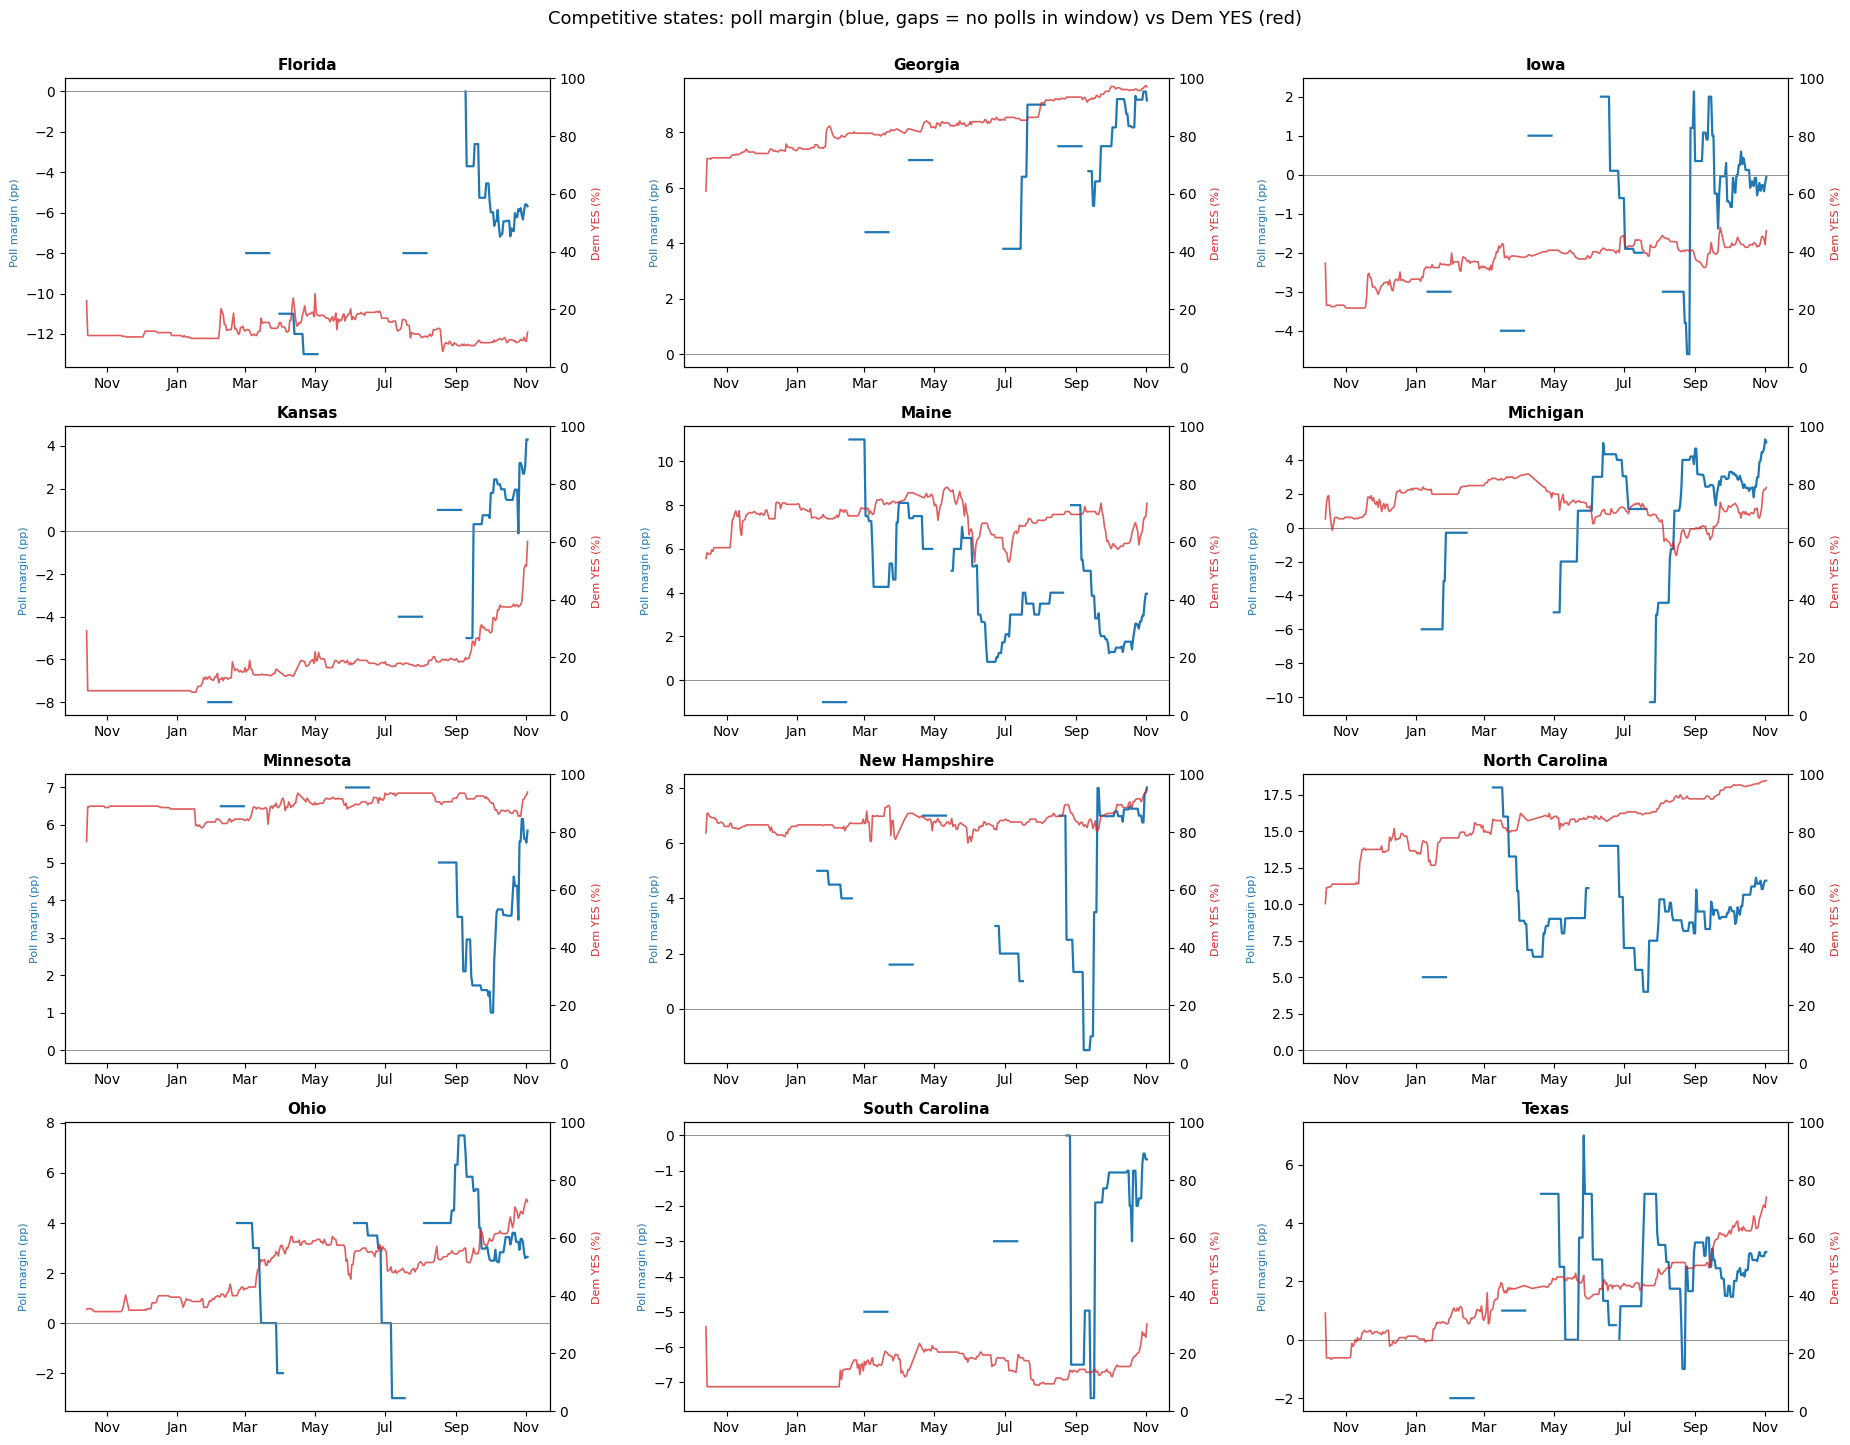

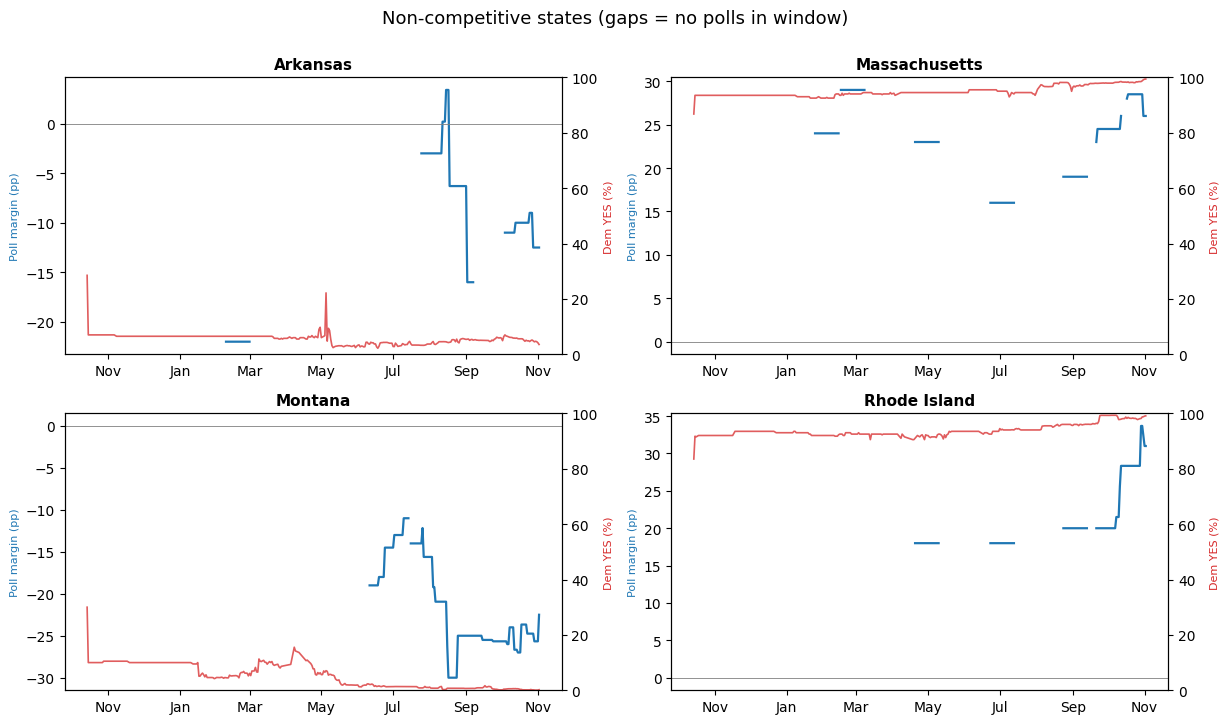

In [ ]:
# ---- density-restricted tests (needs P, mk2, CUT, ols_cl, sample_every from earlier cells) ----

pa_n = poll_avg_n(21)
pn_n = pa_n.merge(mk2[["state", "date", "logit"]], on=["state", "date"])


print("\nWITHIN-STATE LEVELS, weeks with >= k surveys (state fixed effects)")
dL = pd.concat([sample_every(g, 7) for _, g in pn_n.groupby("state")])
for k in (1, 3, 5):
    for lab, dd in (("all 16", dL[dL["n"] >= k]), ("competitive 12", dL[(dL["n"] >= k) & dL["state"].isin(competitive)])):
        m = ols_cl("logit ~ poll_avg + C(state)", dd)
        print(f" k>={k} {lab:15s} n={len(dd):3d} slope={m.params['poll_avg']:+.4f} se={m.bse['poll_avg']:.4f} p={m.pvalues['poll_avg']:.3f}")

# ---- cross-state snapshots: do states with better poll margins have higher market probability? ----
print("\nCROSS-STATE SNAPSHOTS (poll average with >=2 surveys vs market on that day)")
snap_days = ["2026-08-01", "2026-09-01", "2026-10-01", "2026-10-15", "2026-11-01"]
for day in snap_days:
    d = pd.Timestamp(day)
    s = pa_n[(pa_n["date"] == d) & (pa_n["n"] >= 2)].merge(mk2[mk2["date"] == d][["state", "dem_prob", "logit"]], on="state")
    if len(s) < 6: print(f" {day}: only {len(s)} states"); continue
    b, a = np.polyfit(s["poll_avg"], s["logit"], 1)
    r2 = np.corrcoef(s["poll_avg"], s["logit"])[0, 1] ** 2
    print(f" {day}: states={len(s):2d} spearman={s['poll_avg'].corr(s['dem_prob'], method='spearman'):+.2f} "
          f"logit-per-pp={b:+.3f} R2={r2:.2f}")
    if day == snap_days[-1]:
        s["fitted_pct"] = 100 / (1 + np.exp(-(a + b * s["poll_avg"])))
        s["market_minus_fit_pp"] = s["dem_prob"] - s["fitted_pct"]
        print("\n LARGEST MARKET-vs-POLL DISAGREEMENTS ON", day)
        print(s.sort_values("market_minus_fit_pp")[["state", "poll_avg", "n", "dem_prob", "fitted_pct", "market_minus_fit_pp"]]
              .round(1).to_string(index=False))

# ---- fixed charts: gaps in polling become gaps in the line ----
import matplotlib.dates as mdates
def draw2(states, fname, ncols, title):
    nrows = int(np.ceil(len(states) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6.2 * ncols, 3.6 * nrows)); axes = np.atleast_1d(axes).flatten()
    for ax, st in zip(axes, states):
        a = pa_n[pa_n.state == st].set_index("date")["poll_avg"]
        a = a.reindex(pd.date_range(a.index.min(), CUT))            # missing days -> NaN -> line breaks
        m = mk2[mk2.state == st]
        ax.plot(a.index, a.values, color="tab:blue", lw=1.6); ax.axhline(0, color="gray", lw=.6)
        ax.set_ylabel("Poll margin (pp)", color="tab:blue", fontsize=8)
        ax2 = ax.twinx(); ax2.plot(m["date"], m["dem_prob"], color="tab:red", alpha=.75, lw=1.2); ax2.set_ylim(0, 100)
        ax2.set_ylabel("Dem YES (%)", color="tab:red", fontsize=8); ax.set_title(st, fontsize=11, fontweight="bold")
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    for ax in axes[len(states):]: ax.axis("off")
    fig.suptitle(title, fontsize=13, y=1.0); plt.tight_layout(); plt.savefig(fname, dpi=140, bbox_inches="tight"); plt.show()
draw2(sorted(competitive), "fig_competitive12_v2.png", 3, "Competitive states: poll margin (blue, gaps = no polls in window) vs Dem YES (red)")
draw2(sorted(set(P["state"]) - competitive), "fig_noncompetitive4_v2.png", 2, "Non-competitive states (gaps = no polls in window)")

WINDOW SENSITIVITY (weekly change in logit(P_dem) on weekly change in poll margin; k_min = surveys needed in the window at both endpoints)
 window  k_min         sample   n  states  slope    se     p   corr  ci_lo  ci_hi
     14      1         all 16 237      16 -0.005 0.005 0.308 -0.057 -0.015  0.005
     14      1 competitive 12 203      12 -0.004 0.007 0.549 -0.042 -0.017  0.009
     14      3         all 16  70      13  0.008 0.023 0.743  0.054 -0.037  0.053
     14      3 competitive 12  69      12  0.008 0.023 0.744  0.054 -0.038  0.053
     21      1         all 16 300      16 -0.011 0.005 0.045 -0.105 -0.021 -0.000
     21      1 competitive 12 242      12 -0.009 0.007 0.183 -0.080 -0.022  0.004
     21      3         all 16 100      13  0.013 0.014 0.370  0.082 -0.015  0.040
     21      3 competitive 12  94      12  0.010 0.018 0.583  0.056 -0.025  0.045
     30      1         all 16 364      16 -0.005 0.007 0.491 -0.038 -0.018  0.009
     30      1 competitive 12 291      12

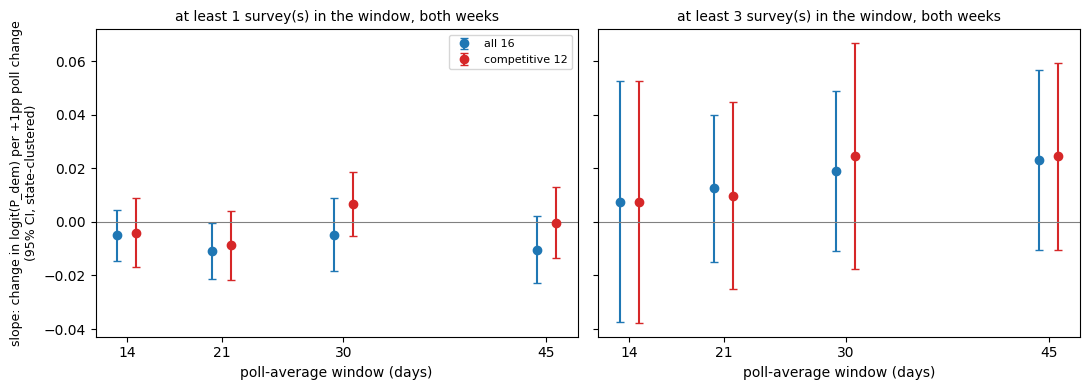


4-WEEK CHANGES, 21-day window  (same period | poll change -> market change in the FOLLOWING 4 weeks)
 k>=1 all 16          same: n= 53 slope=+0.0042 se=0.0066 p=0.526 corr=+0.050
                      next: n= 41 slope=-0.0010 se=0.0115 p=0.929 corr=-0.015
 k>=1 competitive 12  same: n= 42 slope=+0.0061 se=0.0070 p=0.382 corr=+0.078
                      next: n= 33 slope=-0.0063 se=0.0132 p=0.632 corr=-0.088
 k>=3 all 16          same: too few obs
                      next: too few obs
 k>=3 competitive 12  same: too few obs
                      next: too few obs

LEAD-LAG (corr of poll change at t with market change at t+lag weeks; competitive 12, 21-day window)
        corr             n      
k_min      1      3      1     3
lag                             
-3    -0.055  0.030  217.0  96.0
-2    -0.025  0.076  221.0  96.0
-1    -0.048 -0.013  232.0  95.0
 0    -0.080  0.056  242.0  94.0
 1     0.077  0.156  232.0  82.0
 2     0.100  0.153  221.0  70.0
 3     0.156  0.163  209.0 

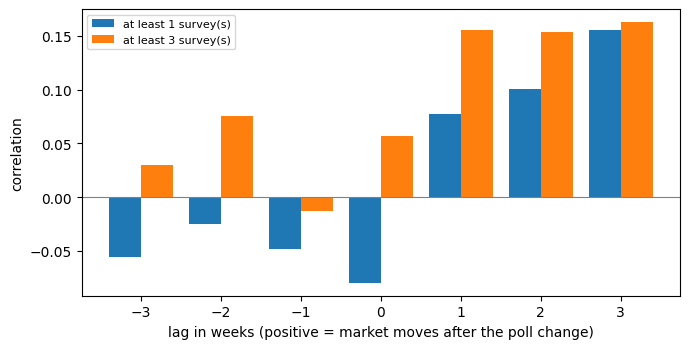

In [ ]:
WINDOWS = (14, 21, 30, 45)
PA = {w: poll_avg_n(w) for w in WINDOWS}              # compute each poll average once

def change_grid(window, k, step=7):
    """Per state, a COMPLETE grid of dates every `step` days starting at the state's first poll average.
    poll_avg is set to NaN where the window holds fewer than k surveys, so a change exists only if
    BOTH endpoints have >= k surveys. Because the grid is complete, shift(-1) is exactly `step` days."""
    out = []
    for st, g in PA[window].groupby("state"):
        grid = pd.date_range(g["date"].min(), CUT, freq=f"{step}D")
        pg = g.set_index("date").reindex(grid)
        pg.loc[pg["n"] < k, "poll_avg"] = np.nan
        lg = mk2[mk2["state"] == st].set_index("date")["logit"].reindex(grid)
        f = pd.DataFrame({"state": st, "poll_avg": pg["poll_avg"], "logit": lg})
        f["d_poll"] = f["poll_avg"].diff()
        f["d_logit"] = f["logit"].diff()
        f["d_logit_next"] = f["d_logit"].shift(-1)    # market change in the FOLLOWING step
        out.append(f.rename_axis("date").reset_index())
    return pd.concat(out, ignore_index=True)

def reg(dd, y="d_logit", x="d_poll"):
    dd = dd.dropna(subset=[x, y])
    if len(dd) < 15 or dd["state"].nunique() < 4:
        return None
    m = ols_cl(f"{y} ~ {x}", dd)
    ci = m.conf_int().loc[x]
    return dict(n=len(dd), states=dd["state"].nunique(), slope=m.params[x], se=m.bse[x],
                p=m.pvalues[x], corr=dd[x].corr(dd[y]), ci_lo=ci[0], ci_hi=ci[1])

def samples(g):
    return (("all 16", g), ("competitive 12", g[g["state"].isin(competitive)]))

# ---------- (1) window sensitivity, weekly changes ----------
rows = []
for w in WINDOWS:
    for k in (1, 3):
        g = change_grid(w, k)
        for lab, dd in samples(g):
            r = reg(dd)
            if r: rows.append(dict(window=w, k_min=k, sample=lab, **r))
win = pd.DataFrame(rows)
print("WINDOW SENSITIVITY (weekly change in logit(P_dem) on weekly change in poll margin; "
      "k_min = surveys needed in the window at both endpoints)")
print(win.round(3).to_string(index=False))
print(f"{len(win)} specifications | expected below 0.05 by chance: {0.05 * len(win):.1f} | Bonferroni threshold: {0.05 / len(win):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, k in zip(axes, (1, 3)):
    for off, (lab, c) in zip((-0.7, 0.7), (("all 16", "tab:blue"), ("competitive 12", "tab:red"))):
        s = win[(win["k_min"] == k) & (win["sample"] == lab)]
        if len(s):
            ax.errorbar(s["window"] + off, s["slope"], yerr=1.96 * s["se"], fmt="o", color=c, capsize=3, label=lab)
    ax.axhline(0, color="gray", lw=.8)
    ax.set_xticks(list(WINDOWS)); ax.set_xlabel("poll-average window (days)")
    ax.set_title(f"at least {k} survey(s) in the window, both weeks", fontsize=10)
axes[0].set_ylabel("slope: change in logit(P_dem) per +1pp poll change\n(95% CI, state-clustered)", fontsize=9)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig("fig_window_sensitivity.png", dpi=140); plt.show()

# ---------- (2) 4-week changes (21-day window) ----------
print("\n4-WEEK CHANGES, 21-day window  (same period | poll change -> market change in the FOLLOWING 4 weeks)")
for k in (1, 3):
    g4 = change_grid(21, k, step=28)
    for lab, dd in samples(g4):
         r, rn = reg(dd), reg(dd, y="d_logit_next")
         txt = lambda q: "too few obs" if q is None else \
             f"n={q['n']:3d} slope={q['slope']:+.4f} se={q['se']:.4f} p={q['p']:.3f} corr={q['corr']:+.3f}"
         print(f" k>={k} {lab:15s} same: {txt(r)}")
         print(f"      {'':15s} next: {txt(rn)}")

# ---------- (3) lead-lag, weekly grid, competitive 12 ----------
# lag > 0: market change `lag` weeks AFTER the poll change.  Shifts are in exact weeks (complete grid).
ll = []
for k in (1, 3):
    g = change_grid(21, k)
    g = g[g["state"].isin(competitive)]
    for lag in range(-3, 4):
        x = pd.DataFrame({"a": g["d_poll"], "b": g.groupby("state")["d_logit"].shift(-lag)}).dropna()
        ll.append(dict(k_min=k, lag=lag, n=len(x), corr=x["a"].corr(x["b"]) if len(x) >= 10 else np.nan))
ll = pd.DataFrame(ll)
print("\nLEAD-LAG (corr of poll change at t with market change at t+lag weeks; competitive 12, 21-day window)")
print(ll.pivot(index="lag", columns="k_min", values=["corr", "n"]).round(3))
print("Note: adjacent weekly changes in a 21-day average overlap, so neighbouring lags are mechanically related.")

fig, ax = plt.subplots(figsize=(7, 3.6))
for off, k in zip((-0.2, 0.2), (1, 3)):
    s = ll[ll["k_min"] == k]
    ax.bar(s["lag"] + off, s["corr"], width=0.4, label=f"at least {k} survey(s)")
ax.axhline(0, color="gray", lw=.8)
ax.set_xlabel("lag in weeks (positive = market moves after the poll change)")
ax.set_ylabel("correlation"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("fig_lead_lag.png", dpi=140); plt.show()

In [ ]:
import statsmodels.formula.api as smf
def lg(p_pct, eps):
    p = (p_pct / 100).clip(eps, 1 - eps); return np.log(p / (1 - p))

def levels_panel(eps):
    m = mk[mk["date"] <= CUT].copy(); m["logit"] = lg(m["dem_prob"], eps)
    x = PA[21].merge(m[["state", "date", "logit"]], on=["state", "date"])
    x = x[((x["date"] - pd.Timestamp("2026-01-02")).dt.days % 7) == 0].copy()   # common weekly grid
    x["wk"] = x["date"].dt.strftime("%Y-%m-%d"); return x

out = []
for eps in (0.01, 0.005):
    x = levels_panel(eps)
    for samp, xs in (("all 16", x), ("competitive 12", x[x["state"].isin(competitive)])):
        for k in (1, 3, 5):
            d = xs[xs["n"] >= k]
            for fe in ("state", "state + week"):
                f = "logit ~ poll_avg + C(state)" + (" + C(wk)" if fe == "state + week" else "")
                m = smf.ols(f, data=d).fit(cov_type="cluster", cov_kwds={"groups": d["state"]}, use_t=True)
                out.append(dict(clip=eps, sample=samp, k=k, fixed_effects=fe, n=len(d), slope=m.params["poll_avg"],
                                se=m.bse["poll_avg"], p=m.pvalues["poll_avg"]))
print("LEVELS: with calendar-week effects, t-based p (df = clusters - 1), and a 0.5% clip")
print(pd.DataFrame(out).round(3).to_string(index=False))

# long difference: change in logit vs change in poll average between two dates, one row per state
def long_diff(start, end="2026-11-01", k=2, eps=0.01):
    m = mk2[["state", "date", "dem_prob"]].copy(); m["logit"] = lg(m["dem_prob"], eps)
    g = lambda df_, dt: df_[df_["date"] == pd.Timestamp(dt)].set_index("state")
    a, b, ma, mb = g(PA[21], start), g(PA[21], end), g(m, start), g(m, end)
    j = pd.concat([a["n"].rename("n0"), a["poll_avg"].rename("p0"), b["n"].rename("n1"), b["poll_avg"].rename("p1"),
                   ma["logit"].rename("l0"), mb["logit"].rename("l1")], axis=1).dropna()
    j = j[(j["n0"] >= k) & (j["n1"] >= k)]
    j["d_poll"] = j["p1"] - j["p0"]; j["d_logit"] = j["l1"] - j["l0"]; return j
print("\nLONG DIFFERENCE (change in market log-odds on change in poll average, one row per state)")
for start in ("2026-09-01", "2026-09-15", "2026-10-01"):
    for k in (1, 2):
        j = long_diff(start, k=k)
        if len(j) < 6: print(f" {start} k>={k}: only {len(j)} states"); continue
        m = smf.ols("d_logit ~ d_poll", data=j).fit(cov_type="HC3")
        ci = m.conf_int().loc["d_poll"]
        print(f" {start} -> 2026-11-01, k>={k}: n={len(j):2d} slope={m.params['d_poll']:+.3f} se={m.bse['d_poll']:.3f} "
         f"95% CI=[{ci[0]:+.3f}, {ci[1]:+.3f}] p={m.pvalues['d_poll']:.3f} "
         f"spearman={j['d_poll'].corr(j['d_logit'], method='spearman'):+.2f}")
print("\nLEAVE-ONE-OUT (Sep 1 -> Nov 1, k>=1)")
j = long_diff("2026-09-01", k=1)
for st in j.index:
    jj = j.drop(st)
    m = smf.ols("d_logit ~ d_poll", data=jj).fit(cov_type="HC3")
    print(f"drop {st:15s} n={len(jj)} slope={m.params['d_poll']:+.3f} p={m.pvalues['d_poll']:.3f}")



LEVELS: with calendar-week effects, t-based p (df = clusters - 1), and a 0.5% clip
 clip         sample  k fixed_effects   n  slope    se     p
0.010         all 16  1         state 362  0.024 0.016 0.143
0.010         all 16  1  state + week 362  0.009 0.016 0.556
0.010         all 16  3         state 124  0.029 0.011 0.026
0.010         all 16  3  state + week 124  0.032 0.021 0.151
0.010         all 16  5         state  67  0.072 0.074 0.352
0.010         all 16  5  state + week  67  0.070 0.036 0.077
0.010 competitive 12  1         state 293  0.029 0.023 0.226
0.010 competitive 12  1  state + week 293  0.006 0.023 0.789
0.010 competitive 12  3         state 115  0.036 0.018 0.063
0.010 competitive 12  3  state + week 115  0.010 0.027 0.729
0.010 competitive 12  5         state  67  0.072 0.074 0.352
0.010 competitive 12  5  state + week  67  0.070 0.036 0.077
0.005         all 16  1         state 362  0.029 0.016 0.095
0.005         all 16  1  state + week 362  0.017 0.020 0.425
0.

In [ ]:
   # Sampling error of one poll margin (simple random sampling; ignores design effects)
   dd = df[["poll_id", "choice", "pct", "sample_size"]].drop_duplicates(["poll_id", "choice"])
   x = (sel[["poll_id", "D", "R"]]
        .merge(dd.rename(columns={"choice": "D", "pct": "pD"}), on=["poll_id", "D"], how="left")
        .merge(dd[["poll_id", "choice", "pct"]].rename(columns={"choice": "R", "pct": "pR"}), on=["poll_id", "R"], how="left"))
   x = x.dropna(subset=["pD", "pR", "sample_size"])
   pD, pR = x["pD"] / 100, x["pR"] / 100
   x["se_margin_pp"] = 100 * np.sqrt((pD + pR - (pD - pR) ** 2) / x["sample_size"])
   print(f"{len(x)} of {len(sel)} selected polls have both shares and a sample size")
   print("standard error of the poll margin (pp): median %.1f | IQR %.1f to %.1f" % (x["se_margin_pp"].median(), *x["se_margin_pp"].quantile([.25, .75])))

458 of 459 selected polls have both shares and a sample size
standard error of the poll margin (pp): median 3.3 | IQR 2.9 to 3.8


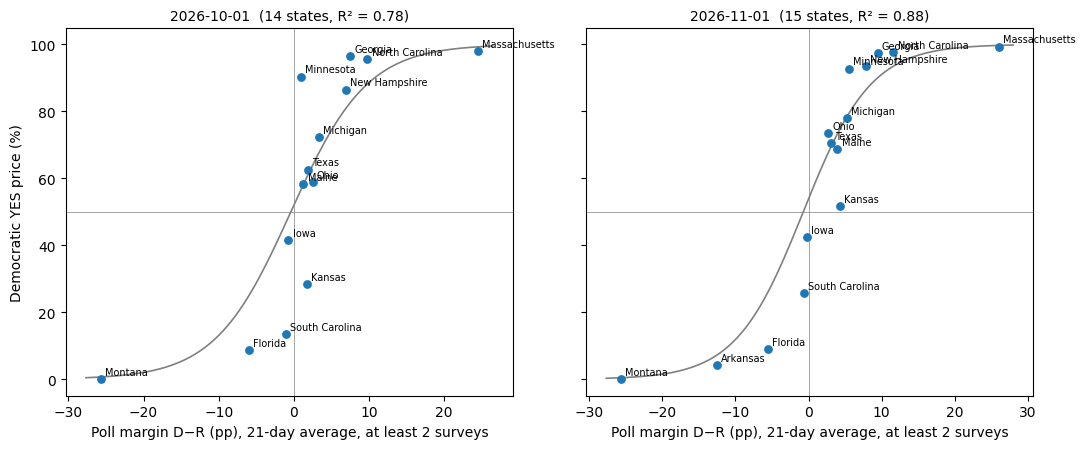

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for ax, day in zip(axes, ["2026-10-01", "2026-11-01"]):
    d = pd.Timestamp(day)
    s = (PA[21][(PA[21]["date"] == d) & (PA[21]["n"] >= 2)]
         .merge(mk2[mk2["date"] == d][["state", "dem_prob", "logit"]], on="state"))
    b, a = np.polyfit(s["poll_avg"], s["logit"], 1)
    xs = np.linspace(s["poll_avg"].min() - 2, s["poll_avg"].max() + 2, 200)
    ax.plot(xs, 100 / (1 + np.exp(-(a + b * xs))), color="gray", lw=1.2)
    ax.scatter(s["poll_avg"], s["dem_prob"], s=28, color="tab:blue", zorder=3)
    for _, r in s.iterrows():
        ax.annotate(r["state"], (r["poll_avg"], r["dem_prob"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.axvline(0, color="gray", lw=.5); ax.axhline(50, color="gray", lw=.5)
    r2 = np.corrcoef(s["poll_avg"], s["logit"])[0, 1] ** 2
    ax.set_title(f"{day}  ({len(s)} states, R² = {r2:.2f})", fontsize=10)
    ax.set_xlabel("Poll margin D−R (pp), 21-day average, at least 2 surveys")
axes[0].set_ylabel("Democratic YES price (%)")
plt.tight_layout(); plt.savefig("fig_cross_state_fit.png", dpi=150); plt.show()

In [ ]:
ks_poll = PA[21][PA[21]["state"] == "Kansas"].set_index("date")
ks_mkt  = mk2[mk2["state"] == "Kansas"].set_index("date")["dem_prob"]
dates = list(pd.date_range("2026-08-03", "2026-10-26", freq="7D")) + [pd.Timestamp("2026-11-01"), pd.Timestamp("2026-11-02")]
print(pd.DataFrame({"market_dem_pct": ks_mkt.reindex(dates), "poll_avg_21d": ks_poll["poll_avg"].reindex(dates),
                    "n_surveys": ks_poll["n"].reindex(dates)}).round(1).to_string())
print("first market price:", ks_mkt.index.min().date(), round(ks_mkt.iloc[0], 1))
print("first poll average:", ks_poll.index.min().date(), round(ks_poll["poll_avg"].iloc[0], 1))

            market_dem_pct  poll_avg_21d  n_surveys
date                                               
2026-08-03            17.0           NaN        NaN
2026-08-10            19.0           NaN        NaN
2026-08-17            18.5           1.0        1.0
2026-08-24            19.0           1.0        1.0
2026-08-31            19.1           1.0        1.0
2026-09-07            18.6           NaN        NaN
2026-09-14            22.5          -5.0        1.0
2026-09-21            25.9           0.3        3.0
2026-09-28            29.5           0.8        4.0
2026-10-05            32.8           2.4        7.0
2026-10-12            37.5           2.0        6.0
2026-10-19            37.5           1.5        6.0
2026-10-26            37.8           3.2        4.0
2026-11-01            51.6           4.3        8.0
2026-11-02            60.2           4.3        8.0
first market price: 2025-10-14 29.2
first poll average: 2026-01-28 -8.0


In [ ]:
bad = df[df["poll_id"].isin(unc) & df["party_known"].isna()]["poll_id"].unique()
cols = [c for c in ["state_clean", "poll_id", "pollster", "end_date", "choice", "pct", "party_known"] if c in df.columns]
print(df[df["poll_id"].isin(bad)][cols].sort_values(["state_clean", "poll_id"]).to_string(index=False))

state_clean          poll_id         pollster   end_date               choice  pct party_known
    Alabama nyt-3811f61cc411        Remington 2026-05-07          Barry Moore 23.0           R
    Alabama nyt-3811f61cc411        Remington 2026-05-07         Jared Hudson 20.0           R
    Alabama nyt-3811f61cc411        Remington 2026-05-07       Steve Marshall 16.0           R
    Alabama nyt-3811f61cc411        Remington 2026-05-07        Dale Deas Jr.  2.0        None
    Alabama nyt-3811f61cc411        Remington 2026-05-07        Rodney Walker  1.0           R
    Alabama nyt-3811f61cc411        Remington 2026-05-07        Morgan Murphy  1.0           R
    Alabama nyt-3811f61cc411        Remington 2026-05-07          Seth Burton  1.0           R
    Alabama nyt-66ac6aaea4ce Quantus Insights 2026-05-17         Jared Hudson 35.8           R
    Alabama nyt-66ac6aaea4ce Quantus Insights 2026-05-17          Barry Moore 26.9           R
    Alabama nyt-66ac6aaea4ce Quantus Insights 2026

##   Section 4: Analysis 2

In [ ]:
pa = poll_avg_n(21)
days = pd.date_range("2026-08-01", "2026-10-31", freq="7D")        # weekly grid, ends Oct 31
snapshot = pd.Timestamp("2026-11-01")                                # reported separately, not a "week"
rows2, fits2 = [], []
for d in list(days) + [snapshot]:
    s = (pa[(pa["date"] == d) & (pa["n"] >= 2) & pa["state"].isin(competitive)]
         .merge(mk2[mk2["date"] == d][["state", "dem_prob", "logit"]], on="state"))
    if len(s) < 6: continue
    b, a = np.polyfit(s["poll_avg"], s["logit"], 1)
    if b < 0.05: continue
    s["fit_pct"] = 100 / (1 + np.exp(-(a + b * s["poll_avg"])))
    s["resid_pp"] = s["dem_prob"] - s["fit_pct"]
    s["gap_margin_pts"] = (s["logit"] - (a + b * s["poll_avg"])) / b
    s["wrong_side"] = (s["poll_avg"] != 0) & (np.sign(s["poll_avg"]) != np.sign(s["dem_prob"] - 50))
    s["date"] = d; rows2.append(s)
    fits2.append(dict(date=d.date(), states=len(s), slope=b, prob_at_zero_margin=100 / (1 + np.exp(-a)),
                      R2=np.corrcoef(s["poll_avg"], s["logit"])[0, 1] ** 2,
                      spearman=s["poll_avg"].corr(s["dem_prob"], method="spearman"),
                      tie_offset_pts=a / b, implied_sd_pts=1.702 / b))
R3 = pd.concat(rows2, ignore_index=True)
R3.to_csv(dpath("disagreement_weekly_competitive.csv"), index=False)
print("WEEKLY FIT (last row = Nov 1 snapshot). prob_at_zero_margin = market probability the fit gives to a tied poll")
print(pd.DataFrame(fits2).round(2).to_string(index=False))

W = R3[R3["date"] != snapshot]
summ3 = (W.groupby("state").agg(weeks=("date", "nunique"), mean_resid_pp=("resid_pp", "mean"),
                                mean_gap_pts=("gap_margin_pts", "mean"),
                                weeks_ge3=("gap_margin_pts", lambda x: (x.abs() >= 3).sum()),
                                weeks_big15=("resid_pp", lambda x: (x.abs() >= 15).sum()),
                                wrong_side=("wrong_side", "sum")))
summ3["share_ge3"] = (summ3["weeks_ge3"] / summ3["weeks"]).round(2)
print("\nPER-STATE (weekly grid only)"); print(summ3.sort_values("mean_gap_pts").round(1).to_string())
print("PERSISTENT (3+ margin points in >=60% of weeks):", sorted(summ3[summ3["share_ge3"] >= .6].index))

# reproduces the pooled first pass that motivated the competitive-only benchmark
pool = []
for d in days:
    s = pa[(pa["date"] == d) & (pa["n"] >= 2)].merge(mk2[mk2["date"] == d][["state", "dem_prob", "logit"]], on="state")
    if len(s) < 8: continue
    b, a = np.polyfit(s["poll_avg"], s["logit"], 1)
    s["gap"] = (s["logit"] - (a + b * s["poll_avg"])) / b; pool.append(s)
pool = pd.concat(pool); cc = pool[pool["state"].isin(competitive)]
print("\nPooled benchmark: corr(gap, margin) within competitive states =", round(cc["gap"].corr(cc["poll_avg"]), 2), "| n =", len(cc))

print("\nPooled benchmark, mean gap in margin points by state:")
print(cc.groupby("state")["gap"].agg(weeks="count", mean_gap="mean").round(1).to_string())

WEEKLY FIT (last row = Nov 1 snapshot). prob_at_zero_margin = market probability the fit gives to a tied poll
      date  states  slope  prob_at_zero_margin   R2  spearman  tie_offset_pts  implied_sd_pts
2026-08-29       7   0.26                44.55 0.75      0.86           -0.83            6.47
2026-09-05       8   0.21                51.31 0.47      0.67            0.25            7.95
2026-09-12      10   0.27                45.33 0.48      0.60           -0.69            6.29
2026-09-19      11   0.36                42.06 0.59      0.75           -0.88            4.70
2026-09-26      12   0.39                41.00 0.79      0.85           -0.94            4.39
2026-10-03      12   0.38                43.85 0.77      0.78           -0.66            4.51
2026-10-10      12   0.37                41.34 0.91      0.97           -0.94            4.57
2026-10-17      11   0.35                44.46 0.92      0.96           -0.64            4.89
2026-10-24      12   0.35                41.

In [ ]:
rows = []
for thr in (2, 3, 4):
    for share in (0.5, 0.6, 0.7):
        w = W.groupby("state")["gap_margin_pts"].agg(weeks="count", hits=lambda x: (x.abs() >= thr).sum())
        met = sorted(w[w["hits"] / w["weeks"] >= share].index)
        rows.append(dict(margin_threshold=thr, min_share=share, n_states=len(met), states=", ".join(met) or "none"))
print(pd.DataFrame(rows).to_string(index=False))
print(f"state-weeks with |gap| < 3 margin points: {(W['gap_margin_pts'].abs() < 3).mean():.0%} of {len(W)}")

 margin_threshold  min_share  n_states                            states
                2        0.5         3 Kansas, Minnesota, South Carolina
                2        0.6         2                 Kansas, Minnesota
                2        0.7         2                 Kansas, Minnesota
                3        0.5         1                         Minnesota
                3        0.6         0                              none
                3        0.7         0                              none
                4        0.5         1                         Minnesota
                4        0.6         0                              none
                4        0.7         0                              none
state-weeks with |gap| < 3 margin points: 85% of 107


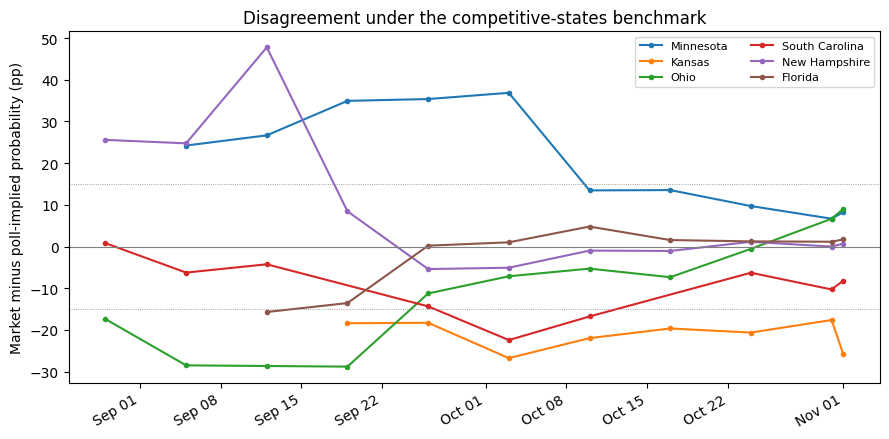

In [ ]:
top = ["Minnesota", "Kansas", "Ohio", "South Carolina", "New Hampshire", "Florida"]
fig, ax = plt.subplots(figsize=(9, 4.5))
for st in top:
    q = R3[R3["state"] == st]; ax.plot(q["date"], q["resid_pp"], marker="o", ms=3, label=st)
ax.axhline(0, color="gray", lw=.8)
for y in (15, -15): ax.axhline(y, color="gray", ls=":", lw=.6)
ax.set_ylabel("Market minus poll-implied probability (pp)")
ax.set_title("Disagreement under the competitive-states benchmark")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d")); fig.autofmt_xdate()
ax.legend(fontsize=8, ncol=2); plt.tight_layout(); plt.savefig("fig_disagreement_competitive.png", dpi=140); plt.show()

In [ ]:
import statsmodels.api as sm
import pandas as pd

# Using your active weekly competitive dataset 'R3'
# with columns: ['date', 'state', 'logit', 'poll_avg']

loo_records = []

for week, week_df in R3.groupby('date'):
    states = week_df['state'].unique()

    for state in states:
        # Exclude the target state for the leave-one-out model
        train_df = week_df[week_df['state'] != state]
        test_df = week_df[week_df['state'] == state]

        # Need at least a couple of points to fit the line
        if len(train_df) < 2:
            continue

        # Fit OLS on N-1 states
        X_train = sm.add_constant(train_df['poll_avg'])
        y_train = train_df['logit']
        model = sm.OLS(y_train, X_train).fit()

        # Predict for the left-out state
        X_test = sm.add_constant(test_df['poll_avg'], has_constant='add')
        pred_log_odds = model.predict(X_test).values[0]
        observed_log_odds = test_df['logit'].values[0]

        # Calculate LOO disagreement (residual)
        disagreement_loo = observed_log_odds - pred_log_odds

        loo_records.append({
            'week': week,
            'state': state,
            'observed_log_odds': observed_log_odds,
            'predicted_loo': pred_log_odds,
            'disagreement_loo': disagreement_loo
        })

df_loo = pd.DataFrame(loo_records)

In [ ]:
# Quick check of mean absolute LOO disagreement vs original
print("Mean absolute LOO disagreement:", df_loo['disagreement_loo'].abs().mean())

Mean absolute LOO disagreement: 0.6353375335652038


## Section 5: Analysis 3

In [ ]:
u = polls_raw[["poll_id", "pollster", "end_date", "source_url"]].drop_duplicates("poll_id").copy()
u["domain"] = u["source_url"].astype(str).str.extract(r"https?://(?:www\.)?([^/]+)")[0]
pat = r"(20\d{2})[-/_]?(0[1-9]|1[0-2])[-/_]?(0[1-9]|[12]\d|3[01])"
u["url_date"] = u["source_url"].astype(str).str.extract(pat).apply(lambda r: "-".join(r) if r.notna().all() else None, axis=1)
print("polls:", len(u), "| missing url:", int(u["source_url"].isna().sum()), "| url contains a date:", int(u["url_date"].notna().sum()))
print(u["domain"].value_counts().head(15))
chk = u[u["url_date"].notna()].assign(end=lambda d: pd.to_datetime(d["end_date"], format="mixed", errors="coerce"),
                                         pub=lambda d: pd.to_datetime(d["url_date"], errors="coerce"))
print("\nDays from fieldwork end to the date in the URL:"); print((chk["pub"] - chk["end"]).dt.days.describe())
display(u.sample(12, random_state=1)[["pollster", "end_date", "source_url"]])

polls: 783 | missing url: 2 | url contains a date: 167
domain
x.com                                       56
insideradvantage.com                        30
scholars.unh.edu                            30
quantusinsights.org                         28
politico.com                                27
nytimes.com                                 25
thetrafalgargroup.org                       24
emersoncollegepolling.com                   23
drive.google.com                            23
d3nkl3psvxxpe9.cloudfront.net               20
docs.google.com                             17
242750075.fs1.hubspotusercontent-na2.net    14
battlegrounds.coefficient.org               13
netchoice.org                               13
static1.squarespace.com                     11
Name: count, dtype: int64

Days from fieldwork end to the date in the URL:
count     167.000000
mean       -4.688623
std       705.299039
min     -6956.000000
25%         0.000000
50%         2.000000
75%         4.000000
max      58

,pollster,end_date,source_url
1962,JMC Enterprises,2026-01-14,https://flemingsenatecampaign.com/new-poll-bil...
716,Emerson College,2026-09-14,https://emersoncollegepolling.com/texas-2026-p...
288,University of Houston Hobby School of Public A...,2026-10-14,https://www.uh.edu/hobby/texas2026/index.php
819,Emerson College,2026-08-29,https://emersoncollegepolling.com/massachusett...
909,Embold Research,2026-08-11,https://salve.edu/news/news-listing/new-survey...
1499,American Pulse Research & Polling,2026-04-01,https://www.americanpulse.us/products/polling-...
1757,Peak Insights,2026-02-23,https://x.com/PatrickSvitek/status/20263974562...
542,Big Data Poll,2026-09-27,https://www.bigdatapoll.com/blog/buckeye-state...
1474,Impact Research,2026-04-12,https://www.splcactionfund.org/wp-content/uplo...
1888,University of Houston/YouGov,2026-01-31,https://www.uh.edu/hobby/primary2026/senate.pdf


surveys in the 16 states: 452
kind
none     354
date      83
exact     15
kind            date  exact  none  All
state                                 
Arkansas           1      1     5    7
Florida            5      0    26   31
Georgia            3      0    15   18
Iowa               6      1    28   35
Kansas             6      1    13   20
Maine             12      0    38   50
Massachusetts      1      0     9   10
Michigan          15      5    38   58
Minnesota          4      2    14   20
Montana            1      2    13   16
New Hampshire      2      0    19   21
North Carolina     2      1    39   42
Ohio               8      1    30   39
Rhode Island       0      0     7    7
South Carolina     4      0    12   16
Texas             13      1    48   62
All               83     15   354  452
days from fieldwork end to publication (dated surveys): {'count': 98.0, '25%': 1.0, '50%': 3.0, '75%': 5.0}

usable events (time known, a prior average exists, +24h inside the market wi

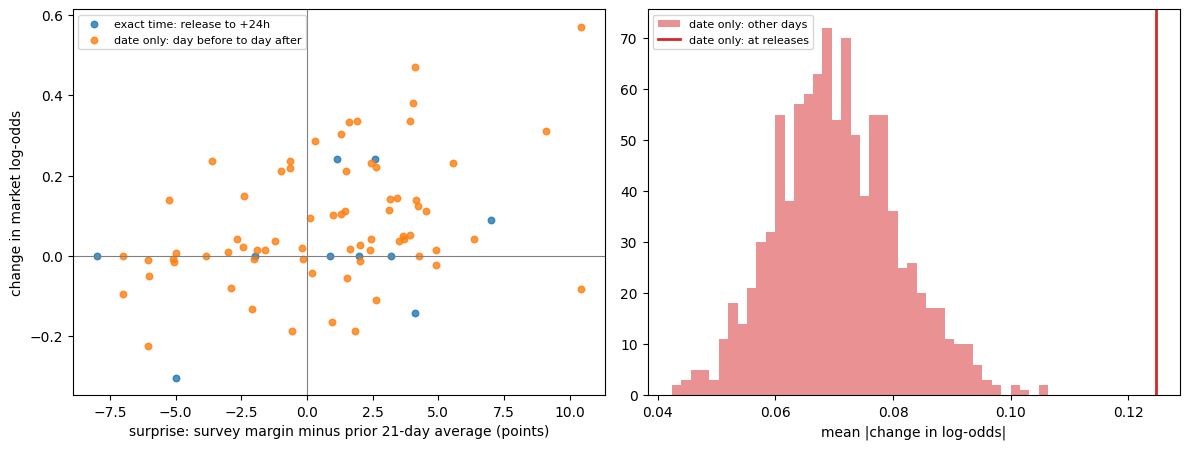

In [ ]:

import re, numpy as np, pandas as pd, matplotlib.pyplot as plt
rng = np.random.default_rng(3)
PRIOR_DAYS, N_PERM, N_CTRL = 21, 5000, 1000
END = pd.Timestamp(CUT, tz="UTC") + pd.Timedelta(days=1)            # market data run to the end of Nov 2 (UTC)
utc_np = lambda s: s.dt.tz_convert("UTC").dt.tz_localize(None).to_numpy("datetime64[ns]")

# ---- 1. publication time of each survey ----
URL_DATE = re.compile(r"(?<!\d)(2026)[-/_.]?(0[1-9]|1[0-2])[-/_.]?(0[1-9]|[12]\d|3[01])(?!\d)")
def x_time(u):
    m = re.search(r"(?:x|twitter)\.com/[^/]+/status/(\d{15,20})", str(u))
    return pd.Timestamp((int(m.group(1)) >> 22) + 1288834974657, unit="ms", tz="UTC") if m else pd.NaT
def url_date(u):
    m = URL_DATE.search(str(u))
    return pd.Timestamp("-".join(m.groups()), tz="UTC") if m else pd.NaT

ev = sel.merge(polls_raw[["poll_id", "source_url"]].drop_duplicates("poll_id"), on="poll_id", how="left")
ev["exact"] = pd.to_datetime(ev["source_url"].map(x_time), utc=True)
ev["dated"] = pd.to_datetime(ev["source_url"].map(url_date), utc=True)
end_utc = ev["end"].dt.tz_localize("UTC")
for c in ("exact", "dated"):
    lag = (ev[c].dt.normalize() - end_utc).dt.days
    ev.loc[(lag < -1) | (lag > 30), c] = pd.NaT
ev["kind"] = np.where(ev["exact"].notna(), "exact", np.where(ev["dated"].notna(), "date", "none"))
ev["pub"] = ev["exact"].where(ev["exact"].notna(), ev["dated"])
ev = ev.assign(_r=ev["kind"].map({"exact": 0, "date": 1, "none": 2})).sort_values(["survey_key", "_r"]).drop_duplicates("survey_key")

print(f"surveys in the 16 states: {len(ev)}")
print(ev["kind"].value_counts().to_string())
print(pd.crosstab(ev["state"], ev["kind"], margins=True).to_string())
lg = (ev["pub"].dt.normalize() - ev["end"].dt.tz_localize("UTC")).dt.days[ev["kind"] != "none"]
print("days from fieldwork end to publication (dated surveys):", lg.describe()[["count", "25%", "50%", "75%"]].round(1).to_dict())

# ---- 2. surprise = this survey's margin minus the mean of the same state's surveys that ended in the 21 days before it ----
def prior(r):
    pr = P[(P["state"] == r["state"]) & (P["survey_key"] != r["survey_key"]) &
           (P["end"] < r["end"]) & (P["end"] >= r["end" ] - pd.Timedelta(days=PRIOR_DAYS))]
    return pd.Series({"prior_avg": pr["margin"].mean(), "n_prior": len(pr)})
ev[["prior_avg", "n_prior"]] = ev.apply(prior, axis=1)
ev["margin"] = ev["survey_key"].map(P.set_index("survey_key")["margin"])
ev["surprise"] = ev["margin"] - ev["prior_avg"]
use = ev[(ev["kind"] != "none") & (ev["n_prior"] >= 1) & (ev["pub"] + pd.Timedelta(hours=25) <= END)].copy()
print(f"\nusable events (time known, a prior average exists, +24h inside the market window): "
      f"{(use['kind'] == 'exact').sum()} exact, {(use['kind'] == 'date').sum()} date-only")

# ---- 3. market prices around each release ----
mh = poly_history_all[["state", "timestamp_utc", "probability_pct"]].copy()          # raw 3-hour series
mh["t"] = pd.to_datetime(mh["timestamp_utc"], utc=True).astype("datetime64[ns, UTC]")
mh = mh[mh["t"] < END].sort_values("t")
pp = (mh["probability_pct"] / 100).clip(0.01, 0.99); mh["L"] = np.log(pp / (1 - pp)); mh = mh[["state", "t", "L"]]
def price_at(states, times):                       # logit price at or just before each time (within 4 hours), else NaN
    q = pd.DataFrame({"state": np.asarray(states), "t": pd.to_datetime(times, utc=True).astype("datetime64[ns, UTC]")})
    q["_i"] = np.arange(len(q))
    o = pd.merge_asof(q.sort_values("t"), mh, on="t", by="state", direction="backward", tolerance=pd.Timedelta("4h"))
    return o.sort_values("_i")["L"].to_numpy()
Ld = mk2.set_index(["state", "date"])["logit"]
def daily_at(states, days):                        # logit of the daily mean price on each (naive UTC) day
    return Ld.reindex(pd.MultiIndex.from_arrays([np.asarray(states), pd.to_datetime(days)])).to_numpy()

H = pd.Timedelta(hours=1); D = pd.Timedelta(days=1)
ex = use[use["kind"] == "exact"].reset_index(drop=True)
L0 = price_at(ex["state"], ex["pub"])
ex["pre_24h"] = L0 - price_at(ex["state"], ex["pub"] - 24 * H)
for h in (6, 12, 24): ex[f"post_{h}h"] = price_at(ex["state"], ex["pub"] + h * H) - L0
dt = use[use["kind"] == "date"].reset_index(drop=True)
dt["day"] = dt["pub"].dt.tz_localize(None).dt.normalize()
dt["react_day"] = daily_at(dt["state"], dt["day"] + D) - daily_at(dt["state"], dt["day"] - D)   # day before -> day after the release day

# ---- 4. tests ----
def direction(d, y, label):
    d = d.dropna(subset=["surprise", y])
    if len(d) < 12 or d["state"].nunique() < 4:
        print(f"  {label:42s} too few events (n={len(d)})"); return
    m = smf.ols(f"{y} ~ surprise", data=d).fit(cov_type="cluster", cov_kwds={"groups": d["state"]}, use_t=True)
    ci = m.conf_int().loc["surprise"]
    b5 = 5 * m.params["surprise"]
    x, v = d["surprise"].to_numpy(), d[y].to_numpy(); xc, vc = x - x.mean(), v - v.mean()
    perm = (xc[np.array([rng.permutation(len(x)) for _ in range(N_PERM)])] @ vc) / (xc @ xc)
    perm = perm[~np.isnan(perm)]
    p_perm = (np.abs(perm) >= abs(m.params["surprise"])).mean() if len(perm) else np.nan
    print(f"  {label:42s} n={len(d):3d} slope={m.params['surprise']:+.4f} se={m.bse['surprise']:.4f} "
          f"p_cluster_t= {m.pvalues['surprise']:.3f} p_perm={p_perm:.3f} corr={d['surprise'].corr(d[y]):+.2f}"
          f" | 95% CI=[{ci[0]:+.4f}, {ci[1]:+.4f}] | +5 pt surprise: {b5:+.3f} log-odds = {100*(1/(1+np.exp(-b5))-0.5):+.1f} pts at 50%")

def magnitude(states, base, move, label):
    """Mean |price move| around real releases vs the same state's price at times 2 to 14 days earlier or later (same clock time)."""
    n = len(states); real = np.nanmean(np.abs(move(states, base)))
    offs = rng.choice([o for o in range(-14, 15) if abs(o) >= 2], size=(N_CTRL, n))
    st_rep, b_rep = np.tile(np.asarray(states), N_CTRL), np.tile(base, N_CTRL) + pd.to_timedelta(offs.ravel(), unit="D").to_numpy()
    c = np.abs(move(st_rep, b_rep)).reshape(N_CTRL, n)
    ctrl = np.nanmean(c, axis=1)
    print(f"  {label:42s} n={n:3d} mean|move| at releases={real:.4f} | same state, other days: median={np.nanmedian(ctrl):.4f} "
          f"| share of placebo draws >= real: {(ctrl >= real).mean():.3f}")
    return real, ctrl

mv_hour = lambda s, t: price_at(s, pd.to_datetime(t, utc=True) + 24 * H) - price_at(s, pd.to_datetime(t, utc=True))
mv_day  = lambda s, t: daily_at(s, pd.to_datetime(t) + D) - daily_at(s, pd.to_datetime(t) - D)
print("\n=== DIRECTION: does the price move with the size of the surprise? (logit change per +1 point of surprise) ===")
for lab, e, dd in (("all 16 states", ex, dt), ("competitive 12", ex[ex["state"].isin(competitive)], dt[dt["state"].isin(competitive)])):
    for h in (6, 12, 24): direction(e, f"post_{h}h", f"exact time, +{h}h, {lab}")
    direction(dd, "react_day", f"date only, day before to day after, {lab}")
direction(ex, "pre_24h", "exact time, 24h BEFORE release (should be ~0)")
print("\n=== MAGNITUDE: do prices move more around releases than on other days? ===")
rx = magnitude(ex["state"].to_numpy(), utc_np(ex["pub"]), mv_hour, "exact time, release to +24h") if len(ex) >= 12 else None
ord = magnitude(dt["state"].to_numpy(), dt["day"].to_numpy("datetime64[ns]"), mv_day, "date only, day before to day after") if len(dt) >= 12 else None

# ---- 5. figure ----
fig, a = plt.subplots(1, 2, figsize=(12, 4.6))
for d, y, c, lab in ((ex, "post_24h", "tab:blue", "exact time: release to +24h"), (dt, "react_day", "tab:orange", "date only: day before to day after")):
    q = d.dropna(subset=["surprise", y])
    if len(q): a[0].scatter(q["surprise"], q[y], c=c, s=22, label=lab, alpha=.8)
a[0].axhline(0, color="gray", lw=.8); a[0].axvline(0, color="gray", lw=.8); a[0].legend(fontsize=8)
a[0].set_xlabel("surprise: survey margin minus prior 21-day average (points)"); a[0].set_ylabel("change in market log-odds")
for r_, c, lab in ((rx, "tab:blue", "exact"), (ord, "tab:red", "date only")):
    if r_:
        a[1].hist(r_[1], bins=40, alpha=.5, color=c, label=f"{lab}: other days");
        a[1].axvline(r_[0], color=c, lw=2, label=f"{lab}: at releases")
a[1].set_xlabel("mean |change in log-odds|"); a[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("fig_poll_release.png", dpi=140); plt.show()
use.to_csv(dpath("analysis3_events.csv"), index=False)

date-only events: 69 | mean surprise +0.77 points | share positive 0.61
 offset_days  n   slope     se      p  mean_abs_move
         -10 69 -0.0019 0.0026 0.4832         0.0587
          -7 69 -0.0013 0.0028 0.6491         0.0734
          -5 69  0.0005 0.0031 0.8761         0.0722
          -3 69  0.0022 0.0044 0.6232         0.1061
           0 69  0.0160 0.0056 0.0158         0.1247
           3 46  0.0108 0.0033 0.0075         0.0803
           5 39  0.0022 0.0047 0.6425         0.0625
           7 36  0.0007 0.0040 0.8657         0.0518
          10 34  0.0020 0.0014 0.1917         0.0596
9 offsets | Bonferroni threshold: 0.0056


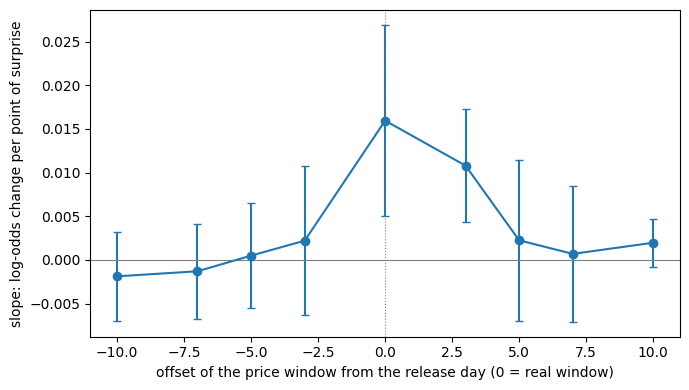

In [ ]:

print(f"date-only events: {len(dt)} | mean surprise {dt['surprise'].mean():+.2f} points | share positive {(dt['surprise'] > 0).mean():.2f}")
rows = []
for o in (-10, -7, -5, -3, 0, 3, 5, 7, 10):
    y = daily_at(dt["state"], dt["day"] + pd.Timedelta(days=o + 1)) - daily_at(dt["state"], dt["day"] + pd.Timedelta(days=o - 1))
    d = dt.assign(y=y).dropna(subset=["surprise", "y"])
    m = smf.ols("y ~ surprise", data=d).fit(cov_type="cluster", cov_kwds={"groups": d["state"]}, use_t=True)   # t-based p, G-1 df
    rows.append(dict(offset_days=o, n=len(d), slope=m.params["surprise"], se=m.bse["surprise"], p=m.pvalues["surprise"],
                     mean_abs_move=np.abs(d["y"]).mean()))
R = pd.DataFrame(rows)
print(R.round(4).to_string(index=False))
print(f"{len(R)} offsets | Bonferroni threshold: {0.05 / len(R):.4f}")
fig, a = plt.subplots(figsize=(7, 4))
a.errorbar(R["offset_days"], R["slope"], yerr=1.96 * R["se"], fmt="o-", capsize=3)
a.axhline(0, color="gray", lw=.8); a.axvline(0, color="gray", lw=.8, ls=":")
a.set_xlabel("offset of the price window from the release day (0 = real window)")
a.set_ylabel("slope: log-odds change per point of surprise")
plt.tight_layout(); plt.savefig("fig_poll_release_placebo.png", dpi=140); plt.show()

## Section 6: Analysis 4

In [ ]:
# Load the FROZEN civicAPI results (no download by default).
# To re-pull on purpose, set FETCH_RESULTS = True; this saves a new timestamped file and uses it.
import json, re, datetime, requests
import pandas as pd

FETCH_RESULTS = False
RESULTS_JSON  = "civicapi_race_87528_20261111_0903UTC.json"   # the file the paper cites

if FETCH_RESULTS:
    resp = requests.get("https://civicapi.org/api/v2/race/87528", timeout=15)
    resp.raise_for_status()
    data = resp.json()
    RESULTS_JSON = f"civicapi_race_87528_{datetime.datetime.now(datetime.timezone.utc):%Y%m%d_%H%M}UTC.json"
    with open(dpath(RESULTS_JSON), "w") as f:
        json.dump(data, f)
else:
    with open(dpath(RESULTS_JSON)) as f:
        data = json.load(f)

rows = []
for code, s in data["region_results"].items():
    for c in s.get("candidates", []):
        try:
            v = int(str(c.get("votes", 0)).replace(",", "").strip() or 0)
        except ValueError:
            v = 0
        rows.append({"State Code": code.upper(), "State Name": s.get("name", code),
                     "% Reporting": f"{s.get('percent_reporting', 0)}%",
                     "Candidate Name": c.get("name", "N/A"), "Party": c.get("party", "N/A"),
                     "Votes": v, "Percentage": f"{c.get('percent', 0)}%",
                     "Winner Called": "\u2713" if c.get("winner", False) else ""})

res_raw = (pd.DataFrame(rows).sort_values(["State Name", "Votes"], ascending=[True, False])
             .reset_index(drop=True))
res_raw.to_csv(dpath("all_35_us_senate_state_results.csv"), index=False)

m = re.search(r"_(\d{8})_(\d{4})UTC", RESULTS_JSON)
RETRIEVED_TAG = f"{m.group(1)[:4]}-{m.group(1)[4:6]}-{m.group(1)[6:]} {m.group(2)[:2]}:{m.group(2)[2:]} UTC"
print(f"Results file: {RESULTS_JSON} (retrieved {RETRIEVED_TAG}) | "
      f"chamber reporting {data.get('percent_reporting')}% | {res_raw['State Code'].nunique()} states")

Results file: civicapi_race_87528_20261111_0903UTC.json (retrieved 2026-11-11 09:03 UTC) | chamber reporting 93.7% | 35 states


In [ ]:

import numpy as np, pandas as pd

SOURCE    = "CivicAPI race 87528 (United States Senate)"
RETRIEVED = RETRIEVED_TAG

raw = pd.read_csv(dpath("all_35_us_senate_state_results.csv"))
raw.columns = [c.strip() for c in raw.columns]
cols = {"State Name": "state", "% Reporting": "reporting", "Candidate Name": "candidate",
        "Party": "party", "Votes": "votes", "Percentage": "pct", "Winner Called": "called"}
missing = [c for c in cols if c not in raw.columns]
assert not missing, f"columns not found: {missing}; the file has {list(raw.columns)}"

r = raw.rename(columns=cols)[list(cols.values())].copy()
num = lambda s: pd.to_numeric(s.astype(str).str.replace("%", "").str.replace(",", "").str.strip(), errors="coerce")
r["reporting"], r["pct"], r["votes"] = num(r["reporting"]), num(r["pct"]), num(r["votes"])
r["called"] = r["called"].fillna("").astype(str).str.strip().isin(["\u2713", "True", "true", "1", "Yes", "yes"])
r["state"] = r["state"].astype(str).str.strip()
r["party"] = r["party"].fillna("").astype(str)
print(f"{len(r)} candidate rows | {r['state'].nunique()} states | rows with a call: {int(r['called'].sum())}")

rows = []
for st, g in r.groupby("state"):
    g = g.sort_values("votes", ascending=False)
    lead, run = g.iloc[0], g.iloc[1]
    called = g[g["called"]]
    w = called.iloc[0] if len(called) == 1 else None
    d = g[g["party"].str.startswith("Democ")]; rp = g[g["party"].str.startswith("Republ")]
    rows.append(dict(
        state=st, reporting=g["reporting"].iloc[0], n_called=len(called),
        winner=None if w is None else w["candidate"], winner_party=None if w is None else w["party"],
        winner_pct=np.nan if w is None else w["pct"],
        leader=lead["candidate"], leader_party=lead["party"], leader_pct=lead["pct"],
        runner_up=run["candidate"], runner_up_party=run["party"],
        margin_pts=lead["pct"] - run["pct"],
        dem_margin_pts=(d["pct"].max() - rp["pct"].max()) if len(d) and len(rp) else np.nan))
res_state = pd.DataFrame(rows).set_index("state")

# Democratic-win indicator: the outcome that the Democratic YES contract pays on.
res_state["dem_won"] = np.where(res_state["winner"].isna(), np.nan,
                                res_state["winner_party"].fillna("").str.startswith("Democ").astype(float))
res_state["in_16"] = res_state.index.isin(P["state"].unique())
res_state["competitive"] = res_state.index.isin(competitive)

# ---- flags: anything here must be settled before a race counts as a result ----
flags = pd.DataFrame(index=res_state.index)
flags["no_call"]           = res_state["n_called"] == 0
flags["multiple_calls"]    = res_state["n_called"] > 1
flags["call_not_leader"]   = res_state["winner"].notna() & (res_state["winner"] != res_state["leader"])
flags["under_50_pct"]      = res_state["leader_pct"] < 50          # possible runoff rules
flags["reporting_below_95"] = res_state["reporting"] < 95
res_state["flags"] = flags.apply(lambda x: ", ".join(k for k, v in x.items() if v), axis=1)

# ---- do the winners and runners-up match the nominee pairs inferred in Section 4.2? ----
NOMINEES = {  # Appendix B2 (Maine: Jackson from Jul 10; South Carolina: Darline Graham from Jul 11)
    "Arkansas": ("Shoffner", "Cotton"), "Florida": ("Nixon", "Moody"), "Georgia": ("Ossoff", "Collins"),
    "Iowa": ("Turek", "Hinson"), "Kansas": ("Hamilton", "Marshall"), "Maine": ("Jackson", "Collins"),
    "Massachusetts": ("Markey", "Deaton"), "Michigan": ("El-Sayed", "Rogers"),
    "Minnesota": ("Flanagan", "Tafoya"), "Montana": ("Bankhead", "Alme"),
    "New Hampshire": ("Pappas", "Sununu"), "North Carolina": ("Cooper", "Whatley"),
    "Ohio": ("Brown", "Husted"), "Rhode Island": ("Reed", "McKay"),
    "South Carolina": ("Andrews", "Graham"), "Texas": ("Talarico", "Paxton")}
def pair_ok(st):
    names = " | ".join(r.loc[r["state"] == st, "candidate"].astype(str)).lower()
    return all(n.lower() in names for n in NOMINEES[st])
res_state["nominee_pair_in_results"] = [pair_ok(s) if s in NOMINEES else np.nan for s in res_state.index]

res_state["source"], res_state["retrieved"] = SOURCE, RETRIEVED
res_state["called_by"] = "CivicAPI call flag (not yet checked against AP or the state election office)"

show = ["reporting", "winner", "winner_party", "winner_pct", "runner_up", "margin_pts", "dem_margin_pts", "dem_won", "flags"]
print("\n=== THE 16 ANALYSIS STATES ===")
print(res_state[res_state["in_16"]][show + ["nominee_pair_in_results"]].round(2).to_string())
print("\n=== OTHER STATES ===")
print((res_state.loc[res_state["in_16"], "reporting"] >= 95).sum(), "of 16 at >=95%")
print(res_state[~res_state["in_16"]][show].round(2).to_string())
bad = res_state[(res_state["flags"] != "") | (res_state["nominee_pair_in_results"] == False)]
print(f"\n{len(bad)} races need attention before use:")
print(bad[["winner", "leader", "reporting", "flags", "nominee_pair_in_results"]].to_string())

res_state.to_csv(dpath("results_by_state.csv"))

260 candidate rows | 35 states | rows with a call: 34

=== THE 16 ANALYSIS STATES ===
                reporting            winner winner_party  winner_pct         runner_up  margin_pts  dem_margin_pts  dem_won                             flags nominee_pair_in_results
state                                                                                                                                                                                
Arkansas            90.13        Tom Cotton   Republican       54.26   Hallie Shoffner       11.85          -11.85      0.0                reporting_below_95                    True
Florida             92.72      Ashley Moody   Republican       50.86       Angie Nixon        2.86           -2.86      0.0                reporting_below_95                    True
Georgia             89.59        Jon Ossoff   Democratic       59.03      Mike Collins       18.06           18.06      1.0                reporting_below_95                    True
Iowa

scored races: 34 of 35 | not scored (no call): ['Alaska']
third-party contender (head-to-head poll margin not comparable): ['Montana']

missing market price on a horizon date: 0 | missing poll average (16 states): 0

=== WINNER IDENTIFICATION AND BRIER SCORE (all called races) ===
horizon                           group  n_market  market_correct  market_brier  n_matched  market_brier_matched  poll_correct  poll_brier_sd4.0  poll_brier_sd5.0  poll_brier_sd6.0
  final              all scored markets        34           0.912         0.058         15                 0.080         0.867             0.051             0.058             0.066
  final 15 head-to-head analysis states        15           0.867         0.080         15                 0.080         0.867             0.051             0.058             0.066
  final                  competitive 12        12           0.833         0.100         12                 0.100         0.833             0.064             0.072             

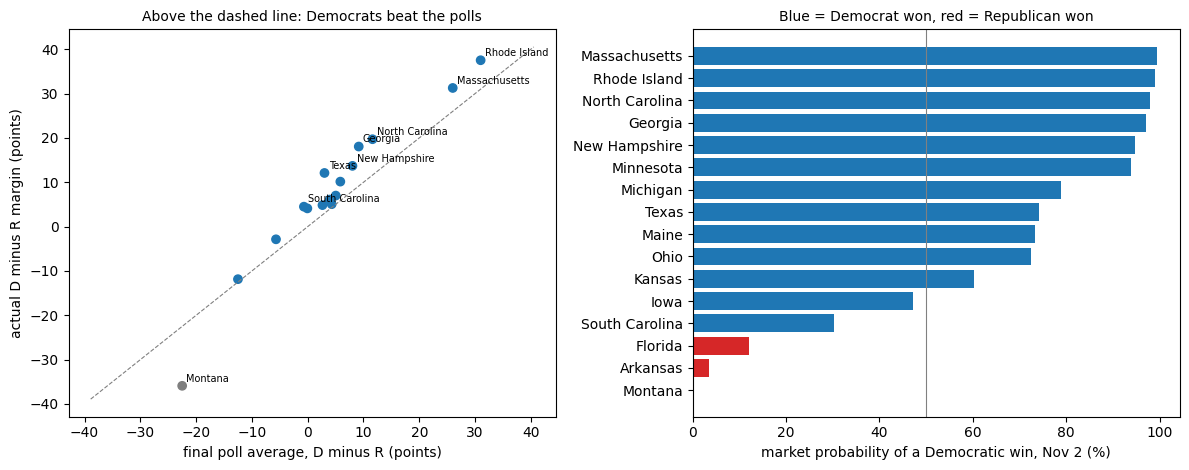

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import norm

ELECTION = pd.Timestamp("2026-11-03")
HORIZONS = {"final": CUT,
            "7d":  ELECTION - pd.Timedelta(days=7),
            "14d": ELECTION - pd.Timedelta(days=14),
            "30d": ELECTION - pd.Timedelta(days=30)}
SIGMAS = (4.0, 5.0, 6.0)     # ASSUMED polling-error SD (margin points): protocol value 5, with 4 and 6 as sensitivity
pd.set_option("display.width", 200)

# ---- 1. results we can score: a called winner only ----
scored = res_state[res_state["dem_won"].notna()].copy()
scored["third_party_contender"] = ~(scored["winner_party"].fillna("").str.startswith(("Democ", "Republ"))
                                    & scored["runner_up_party"].fillna("").str.startswith(("Democ", "Republ")))
print(f"scored races: {len(scored)} of {len(res_state)} | not scored (no call): {sorted(res_state.index[res_state["dem_won"].isna()])}")
print("third-party contender (head-to-head poll margin not comparable):",
      sorted(scored.index[scored["third_party_contender" ] & scored["in_16"]]))

# ---- 2. market probability and poll average on each horizon date ----
mday = mk2.set_index(["state", "date"])["dem_prob"]
pa21 = PA[21].set_index(["state", "date"]
)
rows = []
for st, o in scored.iterrows():
    for h, d in HORIZONS.items():
        rows.append(dict(state=st, horizon=h, date=d, y=o["dem_won"],
                         market=mday.get((st, d), np.nan),
                         poll=pa21["poll_avg"].get((st, d), np.nan),
                         n_polls=pa21["n"].get((st, d), np.nan),
                         in_16=o["in_16"], competitive=o["competitive"], reporting=o["reporting"], third_party=o["third_party_contender"]))
L = pd.DataFrame(rows)
print("\nmissing market price on a horizon date:", int(L["market"].isna().sum()),
      "| missing poll average (16 states):", int(L.loc[L["in_16"], "poll"].isna().sum()))

# ---- 3. winner identification and Brier score ----
def summarise(d, label):
    m = d.dropna(subset=["market"])
    out = dict(group=label, n_market=len(m),
               market_correct=((m["market"] > 50) == (m["y"] == 1)).mean() if len(m) else np.nan,
               market_brier=((m["market"] / 100 - m["y"]) ** 2).mean() if len(m) else np.nan)
    b = d.dropna(subset=["market", "poll"]); b = b[(b["poll" ] != 0) & (~b["third_party"])]          # matched: same races for both sources
    out["n_matched"] = len(b)
    out["market_brier_matched"] = ((b["market" ] / 100 - b["y"]) ** 2).mean() if len(b) else np.nan
    out["poll_correct" ] = ((b["poll"] > 0) == (b["y" ] == 1)).mean() if len(b) else np.nan
    for s in SIGMAS:
        out[f"poll_brier_sd{s}"] = ((norm.cdf(b["poll"] / s) - b["y"]) ** 2).mean() if len(b) else np.nan
    return out

def table(L_, title):
    rows = []
    for h in HORIZONS:
        x = L_[L_["horizon"] == h]
        for lab, d in (("all scored markets", x), ("15 head-to-head analysis states", x[x["in_16"] & ~x["third_party"]]),
                       ("competitive 12", x[x["competitive"]])):
            rows.append(dict(horizon=h, **summarise(d, lab)))
    T = pd.DataFrame(rows)
    print(f"\n=== {title} ===")
    print(T.round(3).to_string(index=False))
    return T
T_all = table(L, "WINNER IDENTIFICATION AND BRIER SCORE (all called races)")
T_95  = table(L[L["reporting"] >= 95], "SAME, restricted to races with at least 95% of votes reported")

# ---- 4. margin error: actual Democratic margin minus the poll average (positive = Democrats beat the polls) ----
fin = L[L["horizon" ] == "final"].merge(scored[["dem_margin_pts", "third_party_contender", "winner"]], left_on="state", right_index=True)
fin = fin[fin["in_16"]].dropna(subset=["poll", "dem_margin_pts"]).copy()
fin["error"] = fin["dem_margin_pts" ] - fin["poll"]
print("\n=== MARGIN ERROR AT THE FINAL HORIZON (16 analysis states) ===")
print(fin.set_index("state")[["poll", "n_polls", "dem_margin_pts", "error", "third_party_contender"]
].sort_values("error").round(1).to_string())
for lab, d in (("all with a head-to-head poll", fin), ("excluding third-party contenders", fin[~fin["third_party_contender"]])):
    e = d["error"]
    print(f"{lab}: n={len(e)} mean signed error={e.mean():+.2f} | MAE={e.abs().mean():.2f} | RMSE={np.sqrt((e**2).mean()):.2f} "
          f"| Democrats beat the poll average in {(e > 0).sum()} of {len(e)}")
print("Note: one polling miss in the same direction in many states is one national error, not many independent ones.")
e = fin[~fin["third_party_contender"]]["error"]
print(f"common shift = {e.mean()**2 / (e**2).mean():.0%} of the mean squared error | SD of errors around the mean: {e.std(ddof=0):.1f} points")

# ---- 5. calibration of the market at the final horizon (few races: read with great care) ----
c = L[(L["horizon"] == "final") & L["market"].notna()].copy()
c["bin"] = pd.cut(c["market"], [-0.01, 10, 50, 90, 100.01], labels=["0-10%", "10-50%", "50-90%", "90-100%"])
cal = c.groupby("bin", observed=True).agg(races=("y", "size"), mean_market=("market", "mean"), share_dem_won=("y", "mean"))
cal["share_dem_won"] *= 100
print("\n=== MARKET CALIBRATION, final horizon (percent) ===")
print(cal.round(1).to_string())

# ---- 6. focus cases and the twelve competitive states, every horizon ----
W = (L[L["competitive"]].pivot(index="state", columns="horizon", values="market")[list(HORIZONS)].round(1)
     .join(L[(L["competitive"]) & (L["horizon"] == "final")].set_index("state")[["poll"]].rename(columns={"poll": "poll_final"}).round(1))
     .join(scored[["winner", "dem_margin_pts"]]))
W["focus"] = np.where(W.index.isin(["Minnesota", "Kansas", "Iowa"]), "focus case", "")
print("\n=== COMPETITIVE 12: market probability (%) by horizon, final poll average, result ===")
print(W.to_string())

# Build DataFrame specifically to keep the to_string() method functional
imp_df = L[L["competitive"]].pivot(index="state", columns="horizon", values="poll")[list(HORIZONS)]
imp = (100 * norm.cdf(imp_df / 5)).round(1)
imp = pd.DataFrame(imp, index=imp_df.index, columns=imp_df.columns)
print("\nPoll-implied probability of a Democratic win (SD 5), competitive 12:")
print(imp.to_string())

# ---- 7. figure: poll vs actual margin, and market probability by outcome ----
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
a = ax[0]; f16 = fin.set_index("state")
a.scatter(f16["poll"], f16["dem_margin_pts"], c=np.where(f16["third_party_contender"], "tab:gray", "tab:blue"))
lim = [min(f16["poll"].min(), f16["dem_margin_pts"].min()) - 3, max(f16["poll"].max(), f16["dem_margin_pts"].max()) + 3]
a.plot(lim, lim, color="gray", lw=.8, ls="--")
for st, r_ in f16.iterrows():                      # label only the larger misses, to keep the middle readable
    if abs(r_["dem_margin_pts"] - r_["poll"]) >= 5: a.annotate(st, (r_["poll"], r_["dem_margin_pts"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
a.set_xlabel("final poll average, D minus R (points)"); a.set_ylabel("actual D minus R margin (points)")
a.set_title("Above the dashed line: Democrats beat the polls", fontsize=10)
b = ax[1]; m = L[(L["horizon"] == "final") & L["in_16"]].dropna(subset=["market"]).sort_values("market")
b.barh(m["state"], m["market"], color=np.where(m["y"] == 1, "tab:blue", "tab:red"))
b.axvline(50, color="gray", lw=.8); b.set_xlabel("market probability of a Democratic win, Nov 2 (%)")
b.set_title("Blue = Democrat won, red = Republican won", fontsize=10)
plt.tight_layout(); plt.savefig("fig_forecast_evaluation.png", dpi=140); plt.show()

In [ ]:
# ---- CHECK: publication-lag sensitivity. Read the poll average LAG days before each horizon date. ----
LAGS = (0, 3, 5)                                   # 0 = the baseline reported in the paper
lag_rows = []
for lag in LAGS:
    lagged = [pa21["poll_avg"].get((st, d - pd.Timedelta(days=lag)), np.nan) for st, d in zip(L["state"], L["date"])]
    Ll = L.assign(poll=lagged)                     # same table, poll average read `lag` days earlier
    for h in HORIZONS:
        s = summarise(Ll[(Ll["horizon"] == h) & Ll["in_16"]], "16 analysis states")
        lag_rows.append(dict(lag_days=lag, horizon=h, n_matched=s["n_matched"], market_brier=s["market_brier_matched"],
                             poll_correct=s["poll_correct"], **{k: s[k] for k in s if k.startswith("poll_brier")}))
print("\n=== PUBLICATION-LAG CHECK (16 analysis states; poll average read LAG days earlier) ===")
print(pd.DataFrame(lag_rows).round(3).to_string(index=False))


=== PUBLICATION-LAG CHECK (16 analysis states; poll average read LAG days earlier) ===
 lag_days horizon  n_matched  market_brier  poll_correct  poll_brier_sd4.0  poll_brier_sd5.0  poll_brier_sd6.0
        0   final         15         0.080         0.867             0.051             0.058             0.066
        0      7d         15         0.122         0.867             0.064             0.071             0.078
        0     14d         15         0.129         0.867             0.088             0.092             0.097
        0     30d         15         0.139         0.867             0.077             0.086             0.093
        3   final         15         0.080         0.867             0.056             0.064             0.073
        3      7d         15         0.122         0.867             0.074             0.080             0.087
        3     14d         15         0.129         0.933             0.071             0.079             0.088
        3     30d       

## Section 7: Analysis 5


In [ ]:
import numpy as np, pandas as pd, statsmodels.formula.api as smf
from scipy.stats import norm, spearmanr

DATES = {"sep1": pd.Timestamp("2026-09-01"), "oct15": pd.Timestamp("2026-10-15"),
         "nov1": pd.Timestamp("2026-11-01"), "final": pd.Timestamp(CUT)}
STATES16 = sorted(P["state"].unique())
by_state = {st: g[["end", "margin"]].reset_index(drop=True) for st, g in P.groupby("state")}

def m_window(w):
    def f(g, d):
        s = g[(g["end"] <= d) & (g["end"] > d - pd.Timedelta(days=w))]
        return s["margin"].mean() if len(s) else np.nan
    return f
def m_recency(g, d, half=14, span=45):
    s = g[(g["end"] <= d) & (g["end"] > d - pd.Timedelta(days=span))]
    if not len(s): return np.nan
    age = (d - s["end"]).dt.days.to_numpy()
    return float(np.average(s["margin"], weights=0.5 ** (age / half)))
def m_smoother(g, d, h=14, min_polls=5):
    s = g[g["end"] <= d]
    if len(s) < min_polls: return np.nan
    x = (s["end"] - d).dt.days.to_numpy().astype(float); y = s["margin"].to_numpy(); w = np.exp(-0.5 * (x / h) ** 2)
    if w.sum() < 1.0: return np.nan
    X = np.column_stack([np.ones_like(x), x])
    beta = np.linalg.lstsq(X * np.sqrt(w)[:, None], y * np.sqrt(w), rcond=None)[0]
    rec = s[s["end"] > d - pd.Timedelta(days=45)]["margin"]
    return float(np.clip(beta[0], rec.min(), rec.max())) if len(rec) else np.nan

METHODS = {"21-day mean (baseline)": m_window(21), "14-day mean": m_window(14), "30-day mean": m_window(30),
           "45-day mean": m_window(45), "recency-weighted": m_recency, "local-linear smoother": m_smoother}
est = {nm: {k: {st: f(by_state[st], d) for st in STATES16} for k, d in DATES.items()} for nm, f in METHODS.items()}

PA21 = PA[21].set_index(["state", "date"]); n21 = PA21["n"]; mkd = mk2.set_index(["state", "date"])["dem_prob"]
def lg(p): p = np.clip(np.asarray(p, float) / 100, .01, .99); return np.log(p / (1 - p))
def ser(fn, idx): return pd.Series([fn(st) for st in idx], index=idx)

missed = {}
rows = []
for nm in METHODS:
    o = {"method": nm}
    for k in ("oct15", "nov1"):                                   # cross-state fit, states with >= 2 surveys in 21 days
        d = DATES[k]; s = pd.DataFrame({"poll": pd.Series(est[nm][k])})
        s["n"] = ser(lambda st: n21.get((st, d), np.nan), s.index); s["mkt"] = ser(lambda st: mkd.get((st, d), np.nan), s.index)
        s = s[(s["n"] >= 2) & s["poll"].notna() & s["mkt"].notna()]
        if len(s) >= 8:
            b = np.polyfit(s["poll"], lg(s["mkt"]), 1)[0]
            o.update({
                f"{k}_states": len(s),
                f"{k}_slope": b,
                f"{k}_R2": np.corrcoef(s["poll"], lg(s["mkt"]))[0, 1] ** 2,
                f"{k}_spearman": spearmanr(s["poll"], s["mkt"])[0]
            })
    j = pd.DataFrame({"p0": pd.Series(est[nm]["sep1"]), "p1": pd.Series(est[nm]["nov1"])})
    j["n0"] = ser(lambda st: n21.get((st, DATES["sep1"]), np.nan), j.index); j["n1"] = ser(lambda st: n21.get((st, DATES["nov1"]), np.nan), j.index)
    j["l0"] = lg(ser(lambda st: mkd.get((st, DATES["sep1"]), np.nan), j.index)); j["l1"] = lg(ser(lambda st: mkd.get((st, DATES["nov1"]), np.nan), j.index))
    j = j[(j["n0"] >= 1) & (j["n1"] >= 1)].dropna(); j["dp"], j["dl"] = j["p1" ] - j["p0"], j["l1" ] - j["l0"]
    if len(j) >= 8:
        m = smf.ols("dl ~ dp", data=j).fit(cov_type="HC3")
        o.update({"longdiff_n": len(j), "longdiff_slope": m.params["dp"], "longdiff_p": m.pvalues["dp"]})
    f = pd.DataFrame({"poll": pd.Series(est[nm]["final"])}).join(res_state[["dem_won", "dem_margin_pts", "winner_party", "runner_up_party"]])
    f = f[f["dem_won"].notna() & f["poll"].notna() & (f["poll"] != 0)]                       # final horizon, Analysis 4
    f = f[f["winner_party"].fillna("").str.startswith(("Democ", "Republ")) & f["runner_up_party"].fillna("").str.startswith(("Democ", "Republ"))]   # head-to-head races only
    o.update({
        "final_races": len(f),
        "final_winners_correct": int(((f["poll"] > 0) == (f["dem_won" ] == 1)).sum()),
        "final_brier_sd5": ((norm.cdf(f["poll"] / 5) - f["dem_won"]) ** 2).mean()
    })
    missed[nm] = sorted(f.index[(f["poll"] > 0) != (f["dem_won"] == 1)])
    h = f[f["winner_party"].fillna("").str.startswith(("Democ", "Republ")) & f["runner_up_party"].fillna("").str.startswith(("Democ", "Republ"))].dropna(subset=["dem_margin_pts"])
    e = h["dem_margin_pts" ] - h["poll"]
    o.update({"bias_n": len(e), "bias_mean": e.mean(), "bias_positive": int((e > 0).sum())})
    rows.append(o)
print("ANALYSIS 5: key results under each averaging method")
print(pd.DataFrame(rows).set_index("method").round(3).T.to_string())

base = pd.Series(est["21-day mean (baseline)"]["nov1"]); ref = ser(lambda st: PA21["poll_avg"].get((st, DATES["nov1"]), np.nan), STATES16)
print("\ncheck, baseline here vs PA[21] on Nov 1, max abs difference:", float((base - ref).abs().max()))

print("\nStates whose winner the poll average missed, by method:")
for k, v in missed.items():
    print(f"  {k:25s}: {v}")

ANALYSIS 5: key results under each averaging method
method                 21-day mean (baseline)  14-day mean  30-day mean  45-day mean  recency-weighted  local-linear smoother
oct15_states                           15.000       14.000       15.000       15.000            15.000                 14.000
oct15_slope                             0.189        0.186        0.200        0.202             0.193                  0.169
oct15_R2                                0.835        0.854        0.842        0.840             0.835                  0.826
oct15_spearman                          0.979        0.930        0.975        0.971             0.968                  0.947
nov1_states                            15.000       15.000       15.000       15.000            15.000                 15.000
nov1_slope                              0.216        0.214        0.221        0.223             0.222                  0.220
nov1_R2                                 0.877        0.894        

In [ ]:
# CELL: EXTERNAL AGGREGATOR SNAPSHOTS. Hand-collected and frozen; every row has a source and dates.
# dem_minus_rep = Democratic minus Republican margin in points. Negative = Republican ahead.
# PollCheck "Final pre-election averages" (pollcheck.com/midterms-2026). The table shows no exact
# as-of date, so as_of is set to election eve (2026-11-02, the same date as our own final average).
PC = "https://www.pollcheck.com/midterms-2026"
EXT_AGG = pd.DataFrame([
    # state,            aggregator,  as_of,       margin, source, retrieved
    ("Florida",         "PollCheck", "2026-11-02", -6.2, PC, "2026-11-12"),
    ("Georgia",         "PollCheck", "2026-11-02",  9.6, PC, "2026-11-12"),
    ("Iowa",            "PollCheck", "2026-11-02",  0.6, PC, "2026-11-12"),
    ("Kansas",          "PollCheck", "2026-11-02",  3.0, PC, "2026-11-12"),
    ("Maine",           "PollCheck", "2026-11-02",  2.5, PC, "2026-11-12"),
    ("Michigan",        "PollCheck", "2026-11-02",  4.3, PC, "2026-11-12"),
    ("Minnesota",       "PollCheck", "2026-11-02",  4.7, PC, "2026-11-12"),
    ("New Hampshire",   "PollCheck", "2026-11-02",  6.7, PC, "2026-11-12"),
    ("North Carolina",  "PollCheck", "2026-11-02", 10.4, PC, "2026-11-12"),
    ("Ohio",            "PollCheck", "2026-11-02",  2.6, PC, "2026-11-12"),
    ("South Carolina",  "PollCheck", "2026-11-02", -1.1, PC, "2026-11-12"),
    ("Texas",           "PollCheck", "2026-11-02",  3.0, PC, "2026-11-12"),
], columns=["state", "aggregator", "as_of", "dem_minus_rep", "source_url", "retrieved"])

# DDHQ polling averages (D minus R). Source: DDHQ Votes, Senate polling averages page.
DDHQ_URL       = "https://votes.decisiondeskhq.com/polls/office/us-senate"
DDHQ_ASOF      = "2026-11-01"
DDHQ_RETRIEVED = "2026-11-12"
ddhq = {"Florida": -5.6, "Georgia": 9.8, "Iowa": -0.3, "Kansas": 3.7, "Maine": 5.3,
        "Massachusetts": 25.9, "Michigan": 4.6, "Minnesota": 6.3, "New Hampshire": 8.4,
        "North Carolina": 11.0, "Ohio": 2.3, "South Carolina": 0.1, "Texas": 3.4}
EXT_AGG = pd.concat([EXT_AGG, pd.DataFrame(
    [(s, "DDHQ", DDHQ_ASOF, m, DDHQ_URL, DDHQ_RETRIEVED) for s, m in ddhq.items()],
    columns=EXT_AGG.columns)], ignore_index=True)

COMPETITIVE_12 = ["Florida", "Georgia", "Iowa", "Kansas", "Maine", "Michigan", "Minnesota",
                  "New Hampshire", "North Carolina", "Ohio", "South Carolina", "Texas"]
for agg, g in EXT_AGG.groupby("aggregator"):
    missing = sorted(set(COMPETITIVE_12) - set(g["state"]))
    print(f"{agg}: {g['state'].nunique()} states in table | missing of the 12: {missing}")

x = EXT_AGG[EXT_AGG["state"] != "Montana"].copy()
x["as_of"] = pd.to_datetime(x["as_of"])
x["ours_21d"] = [m_window(21)(by_state[s], d) for s, d in zip(x["state"], x["as_of"])]
x["actual"] = x["state"].map(res_state["dem_margin_pts"])
x["agg_error"] = x["actual"] - x["dem_minus_rep"]
x["our_error"] = x["actual"] - x["ours_21d"]
print(x.assign(as_of=x["as_of"].dt.date)[["state", "aggregator", "dem_minus_rep",
      "ours_21d", "actual", "agg_error", "our_error"]].round(1).to_string(index=False))
print(x.groupby("aggregator").agg(states=("state", "nunique"), mean_agg_error=("agg_error", "mean"),
      mean_our_error=("our_error", "mean"), agg_positive=("agg_error", lambda e: int((e > 0).sum()))).round(2))
EXT_AGG.to_csv(dpath("external_aggregators.csv"), index=False)

DDHQ: 13 states in table | missing of the 12: []
PollCheck: 12 states in table | missing of the 12: []
         state aggregator  dem_minus_rep  ours_21d  actual  agg_error  our_error
       Florida  PollCheck           -6.2      -5.7    -2.9        3.3        2.8
       Georgia  PollCheck            9.6       9.2    18.1        8.5        8.9
          Iowa  PollCheck            0.6      -0.1     4.1        3.5        4.2
        Kansas  PollCheck            3.0       4.3     5.1        2.1        0.8
         Maine  PollCheck            2.5       4.0     6.1        3.6        2.1
      Michigan  PollCheck            4.3       5.0     7.0        2.7        2.0
     Minnesota  PollCheck            4.7       5.8    10.1        5.4        4.3
 New Hampshire  PollCheck            6.7       8.0    13.7        7.0        5.7
North Carolina  PollCheck           10.4      11.6    19.7        9.3        8.1
          Ohio  PollCheck            2.6       2.6     4.9        2.3        2.2
South 

## Section 8: Save figures to Drive

In [ ]:
# Copy the saved figures to Drive
for f in glob.glob("/content/*.png"):
    shutil.copy(f, DATA)
print(sorted(f for f in os.listdir(DATA) if f.endswith(".png")))

['fig_competitive12_v2.png', 'fig_cross_state_fit.png', 'fig_disagreement_competitive.png', 'fig_forecast_evaluation.png', 'fig_lead_lag.png', 'fig_noncompetitive4_v2.png', 'fig_poll_release.png', 'fig_poll_release_placebo.png', 'fig_window_sensitivity.png']


## Section 9: REFRESH ONLY (re-downloads Polymarket data)

Skipped unless `REFRESH = True` in Cell 0. After a refresh, re-run from Cell 1.
**Election-day note:** a new pull will include prices after Nov 2. Analysis cells cut at `CUT = 2026-11-02`, so results are unaffected, but keep the original files.

In [ ]:
if REFRESH:
    # Identify actual 2026 statewide Senate events

    event_register = []
    missing = []
    search_log = []

    for state in states:

        query = f"{state} Senate Election Winner"

        response = requests.get(
            f"{GAMMA_BASE}/public-search",
            params={"q": query},
            timeout=30
        )
        response.raise_for_status()

        events = response.json().get("events", [])

        expected_title = normalize(query)

        # Match exact statewide title AND 2026 election end date
        matches = []

        for event in events:

            title = normalize(event.get("title", ""))

            end_date = pd.to_datetime(
                event.get("endDate"),
                errors="coerce",
                utc=True
            )

            correct_title = title == expected_title

            correct_year = (
                pd.notna(end_date) and
                end_date.year == 2026 and
                end_date.month == 11 and
                end_date.day == 4
            )

            if correct_title and correct_year:
                matches.append(event)

        search_log.append({
            "state": state,
            "search_results": len(events),
            "valid_matches": len(matches)
        })

        if len(matches) == 1:

            event = matches[0]

            event_register.append({
                "state": state,
                "event_id": event.get("id"),
                "event_title": event.get("title"),
                "event_slug": event.get("slug"),
                "start_date": event.get("startDate"),
                "end_date": event.get("endDate")
            })

        else:

            missing.append({
                "state": state,
                "valid_matches": len(matches),
                "available_titles": [
                    e.get("title") for e in events
                ]
            })

        time.sleep(0.15)

    # Build results
    event_register = pd.DataFrame(event_register)

    print("EXPECTED RACES:", len(states))
    print("VALID EVENTS FOUND:", len(event_register))
    print("UNRESOLVED RACES:", len(missing))

    print("\nVALID 2026 EVENTS:")
    display(event_register)

    print("\nUNRESOLVED RACES:")
    display(pd.DataFrame(missing))

In [ ]:
if REFRESH:
    # Retrieve contracts from all 35 Senate events

    market_records = []
    failed_events = []

    for row in event_register.itertuples(index=False):

        try:
            r = requests.get(
                f"{GAMMA_BASE}/events/{row.event_id}",
                timeout=30
            )
            r.raise_for_status()

            event = r.json()

            for m in event.get("markets", []):

                question = m.get("question", "")

                outcomes = parse_if_json(m.get("outcomes"))
                token_ids = parse_if_json(m.get("clobTokenIds"))

                yes_token = None

                if isinstance(outcomes, list) and isinstance(token_ids, list):
                    if "Yes" in outcomes:
                        yes_token = token_ids[outcomes.index("Yes")]

                party_level = bool(
                    re.search(
                        r"democrats?|republicans?|democratic party|republican party",
                        question,
                        flags=re.IGNORECASE
                    )
                )

                market_records.append({
                    "state": row.state,
                    "event_id": row.event_id,
                    "event_title": event.get("title"),
                    "market_id": m.get("id"),
                    "question": question,
                    "yes_token_id": yes_token,
                    "volume": m.get("volumeNum"),
                    "liquidity": m.get("liquidityNum"),
                    "active": m.get("active"),
                    "closed": m.get("closed"),
                    "party_level": party_level
                })

            time.sleep(0.15)

        except Exception as e:
            failed_events.append({
                "state": row.state,
                "error": str(e)
            })

    markets_all = pd.DataFrame(market_records)

    print("TOTAL CONTRACTS:", len(markets_all))
    print("EVENTS WITH ERRORS:", len(failed_events))

    print("\nCONTRACTS PER STATE:")
    display(
        markets_all.groupby("state")
        .size()
        .sort_values(ascending=False)
        .to_frame("Contracts")
    )

    print("\nACTIVE CONTRACTS WITH LIQUIDITY:")
    display(
        markets_all[
            (markets_all["active"] == True) &
            (markets_all["liquidity"] > 0)
        ][
            ["state", "question", "market_id",
             "volume", "liquidity", "party_level"]
        ].reset_index(drop=True)
    )

In [ ]:
if REFRESH:
    # Select Democratic YES markets across 34 races

    # Select party-level Democratic contracts
    dem_markets = markets_all[
        (markets_all["party_level"] == True) &
        (markets_all["question"].str.contains(
            "Democrats win",
            case=False,
            na=False
        ))
    ].copy()

    # Check market coverage
    print("Democratic markets found:",
          len(dem_markets))

    print("Unique states:",
          dem_markets["state"].nunique())

    print("\nDuplicate states:")
    display(
        dem_markets[
            dem_markets.duplicated("state", keep=False)
        ][["state", "question", "market_id"]]
    )

    print("\nMissing YES tokens:")
    print(dem_markets["yes_token_id"].isna().sum())

    # Create clean market register
    market_register = dem_markets[
        [
            "state",
            "event_id",
            "event_title",
            "market_id",
            "question",
            "yes_token_id",
            "volume",
            "liquidity"
        ]
    ].copy()

    market_register = market_register.sort_values("state")

    display(market_register.reset_index(drop=True))

In [ ]:
if REFRESH:
    # Retrieve historical prices for all 34 Democratic YES markets

    V2_URL = "https://data-api.polymarket.com/v2/prices-history"

    all_history = []
    raw_market_responses = {}
    failed_markets = []

    for row in market_register.itertuples(index=False):

        print(f"Downloading {row.state}...", end=" ")

        try:
            params = {
                "token_id": str(row.yes_token_id),
                "interval": "max",
                "bucket_seconds": 10800,
                "limit": 10000
            }

            response = requests.get(
                V2_URL,
                params=params,
                timeout=60
            )

            response.raise_for_status()

            payload = response.json()
            records = payload.get("data", [])

            if not records:
                failed_markets.append({
                    "state": row.state,
                    "reason": "No price history returned"
                })
                print("NO DATA")
                continue

            raw_market_responses[row.state] = payload

            temp = pd.DataFrame(records)

            temp["state"] = row.state
            temp["event_id"] = row.event_id
            temp["market_id"] = row.market_id
            temp["yes_token_id"] = str(row.yes_token_id)

            temp["timestamp_utc"] = pd.to_datetime(
                temp["timestamp"],
                unit="s",
                utc=True
            )

            temp["price"] = pd.to_numeric(
                temp["price"], errors="coerce"
            )

            temp["probability_pct"] = temp["price"] * 100

            all_history.append(temp)

            print(f"{len(temp)} observations")

            # Check whether another API page exists
            pagination = payload.get("pagination") or {}
            if pagination.get("next_cursor"):
                print("WARNING: Additional pagination available for", row.state)

            time.sleep(0.2)

        except Exception as e:
            failed_markets.append({
                "state": row.state,
                "reason": str(e)
            })
            print("ERROR:", e)

    # Combine all successfully retrieved histories
    if not all_history:
        raise ValueError("No historical price data was retrieved.")

    poly_history_all = pd.concat(
        all_history,
        ignore_index=True
    )

    poly_history_all = poly_history_all.sort_values(
        ["state", "timestamp_utc"]
    ).reset_index(drop=True)

    # Coverage report
    coverage_all = poly_history_all.groupby("state").agg(
        observations=("price", "count"),
        first_observation=("timestamp_utc", "min"),
        last_observation=("timestamp_utc", "max")
    )

    print("\n========== COLLECTION SUMMARY ==========")
    print("Markets requested:", len(market_register))
    print("Markets retrieved:", len(all_history))
    print("Failed markets:", len(failed_markets))
    print("Total observations:", len(poly_history_all))

    print("\nHISTORICAL COVERAGE:")
    display(coverage_all)

    if failed_markets:
        print("\nFAILED MARKETS:")
        display(pd.DataFrame(failed_markets))

In [ ]:
if REFRESH:
    # Final historical data audit

    print("UNIQUE RACES:", poly_history_all["state"].nunique())
    print("TOTAL OBSERVATIONS:", len(poly_history_all))

    print("\nCOVERAGE BY RACE:")

    coverage_all = (
        poly_history_all.groupby("state")
        .agg(
            observations=("price", "count"),
            first_date=("timestamp_utc", "min"),
            last_date=("timestamp_utc", "max")
        )
        .reset_index()
    )

    display(coverage_all)

    print("\nMISSING PRICE VALUES:",
          poly_history_all["price"].isna().sum())

    print("DUPLICATE TOKEN/TIMESTAMP RECORDS:",
          poly_history_all.duplicated(
              ["yes_token_id", "timestamp_utc"]
          ).sum())

    print("\nAPI PAGINATION CHECK:")

    cursor_states = [
        state for state, payload in raw_market_responses.items()
        if (payload.get("pagination") or {}).get("next_cursor")
    ]

    print("Markets with additional pages:", len(cursor_states))
    print(cursor_states)
    # Save original market extraction

    poly_history_all.to_csv(
        dpath("polymarket_2026_senate_raw.csv"),
        index=False
    )

    market_register.to_csv(
        dpath("polymarket_senate_market_register.csv"),
        index=False
    )

    coverage_all.to_csv(
        dpath("polymarket_historical_coverage.csv"),
        index=False
    )

    print("Market data saved successfully.")

## Section 10: One-time data preparation (how the merged polling file was built; not part of a normal run)

In [ ]:

old = pd.read_csv(dpath("polling_desk_original.csv"))
new = pd.read_csv(dpath("polling_desk_update.csv"))
new["end_dt"] = pd.to_datetime(new["end_date"], format="mixed", errors="coerce")

add = new[~new["poll_id"].isin(old["poll_id"])].copy()
print("polls only in update:", add["poll_id"].nunique(), "| rows:", len(add))
print("populations:", add["population"].value_counts().to_dict(), "| internal:", add["internal"].value_counts().to_dict())
print("end dates:", add["end_dt"].min().date(), "to", add["end_dt"].max().date())
print("ending after Nov 2 cutoff:", add.loc[add["end_dt"] > "2026-11-02", "poll_id"].nunique(), "polls")

keep = add[(add["population"].astype(str).str.lower() == "lv")
           & (add["end_dt"] <= "2026-11-02")
           & add["subject"].str.startswith("2026 ", na=False)]
merged = pd.concat([old, keep[old.columns]], ignore_index=True)
print("merged:", merged.shape, "| polls:", merged["poll_id"].nunique())

BUILD_MERGED = False   # set True only if you really want to rebuild the merged polling file

if BUILD_MERGED:
    merged.to_csv(dpath("polling_desk_merged.csv"), index=False)
    keep[old.columns].to_csv(dpath("polling_desk_added_polls.csv"), index=False)


kp = keep.drop_duplicates("poll_id")                       # one row per poll, not per candidate
st = kp["subject"].str.replace("2026 ", "", regex=False)
print("\nAdded polls by state (our 25 only), counted as polls:")
print(st[st.isin(states_25)].value_counts())

polls only in update: 65 | rows: 170
populations: {'lv': 170} | internal: {False: 170}
end dates: 2026-10-29 to 2026-11-02
ending after Nov 2 cutoff: 0 polls
merged: (2189, 13) | polls: 783

Added polls by state (our 25 only), counted as polls:
subject
Michigan          8
Ohio              8
Maine             6
Texas             5
Iowa              4
Minnesota         4
Kansas            4
New Hampshire     3
North Carolina    3
Florida           3
Georgia           2
South Carolina    2
Colorado          1
New Mexico        1
Illinois          1
Louisiana         1
Rhode Island      1
Massachusetts     1
Name: count, dtype: int64
